# Indian Sign Language Recognition Using Machine Learning

## Project Overview

This project focuses on recognizing Indian Sign Language (ISL) gestures using image preprocessing and Machine Learning techniques.

## Project Objectives
1. Image preprocessing.
2. Develop a Machine Learning model to predict the sign.

In [1]:
# Import the OS library
import os

# Display the current working directory
print(os.getcwd())

C:\Users\vamsi


In [2]:
# Check whether the dataset ZIP file exists
zip_path = "PRAICP-1000-IndiSignLang.zip"

print(os.path.exists(zip_path))

True


In [3]:
# Import ZIP file library
import zipfile

# Extract the dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("ISL_Dataset")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [4]:
# Set the dataset folder path
dataset_path = "ISL_Dataset"

# Display the contents of the dataset folder
print(os.listdir(dataset_path))


['Data']


In [5]:
# Set the main image dataset path
data_path = os.path.join(dataset_path, "Data")

# Identify all category folders
classes = sorted([
    folder for folder in os.listdir(data_path)
    if os.path.isdir(os.path.join(data_path, folder))
])

# Display the categories
print("Sign Categories:", classes)
print("Total Classes:", len(classes))

Sign Categories: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']
Total Classes: 24


In [6]:
# Count images in each category
image_counts = {}

for category in classes:
    folder_path = os.path.join(data_path, category)

    images = [
        file for file in os.listdir(folder_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    image_counts[category] = len(images)

# Display image counts
for category, count in image_counts.items():
    print(f"{category}: {count} images")

# Display total images
print("Total Images:", sum(image_counts.values()))

A: 242 images
B: 259 images
C: 247 images
D: 147 images
E: 243 images
F: 226 images
G: 241 images
H: 116 images
I: 179 images
K: 245 images
L: 182 images
M: 235 images
N: 237 images
O: 229 images
P: 234 images
Q: 216 images
R: 211 images
S: 229 images
T: 216 images
U: 135 images
V: 122 images
W: 128 images
X: 202 images
Y: 251 images
Total Images: 4972


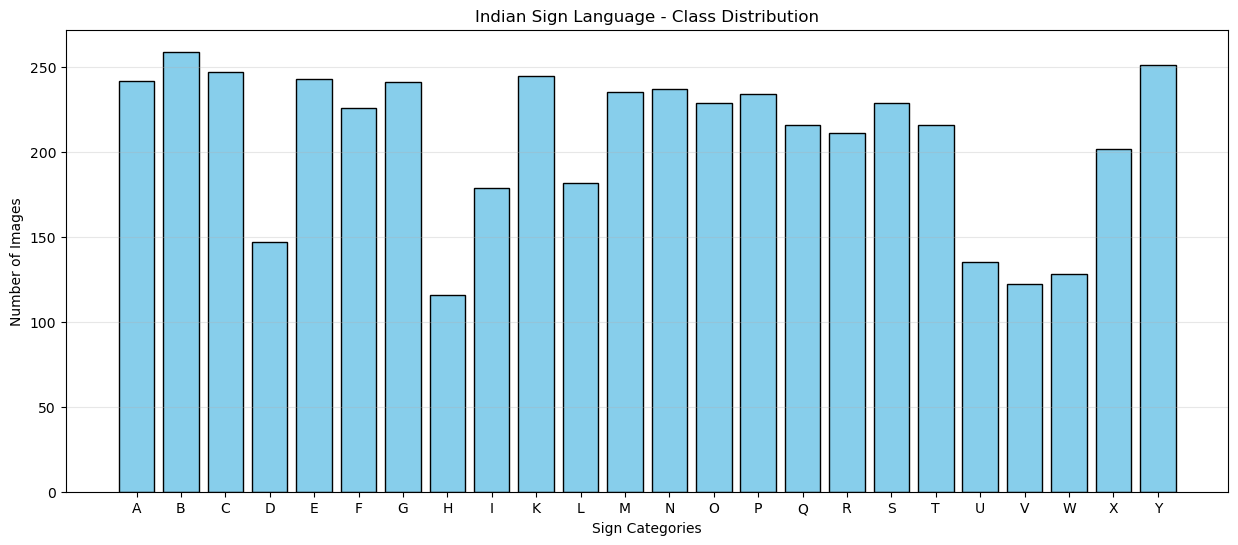

In [7]:
import matplotlib.pyplot as plt

# Create a bar chart
plt.figure(figsize=(15, 6))

plt.bar(image_counts.keys(),
        image_counts.values(),
        color="skyblue",
        edgecolor="black")

plt.title("Indian Sign Language - Class Distribution")
plt.xlabel("Sign Categories")
plt.ylabel("Number of Images")
plt.grid(axis="y", alpha=0.3)

plt.show()

### Class Distribution Analysis

- The dataset contains 4,972 images distributed across 24 sign categories.
- Class B contains the highest number of images (259).
- Class H contains the lowest number of images (116).
- The dataset shows a moderate class imbalance.
- Classes H, U, V and W contain relatively fewer images.
- Class imbalance may affect model prediction performance.
- Appropriate techniques will be considered during model development.

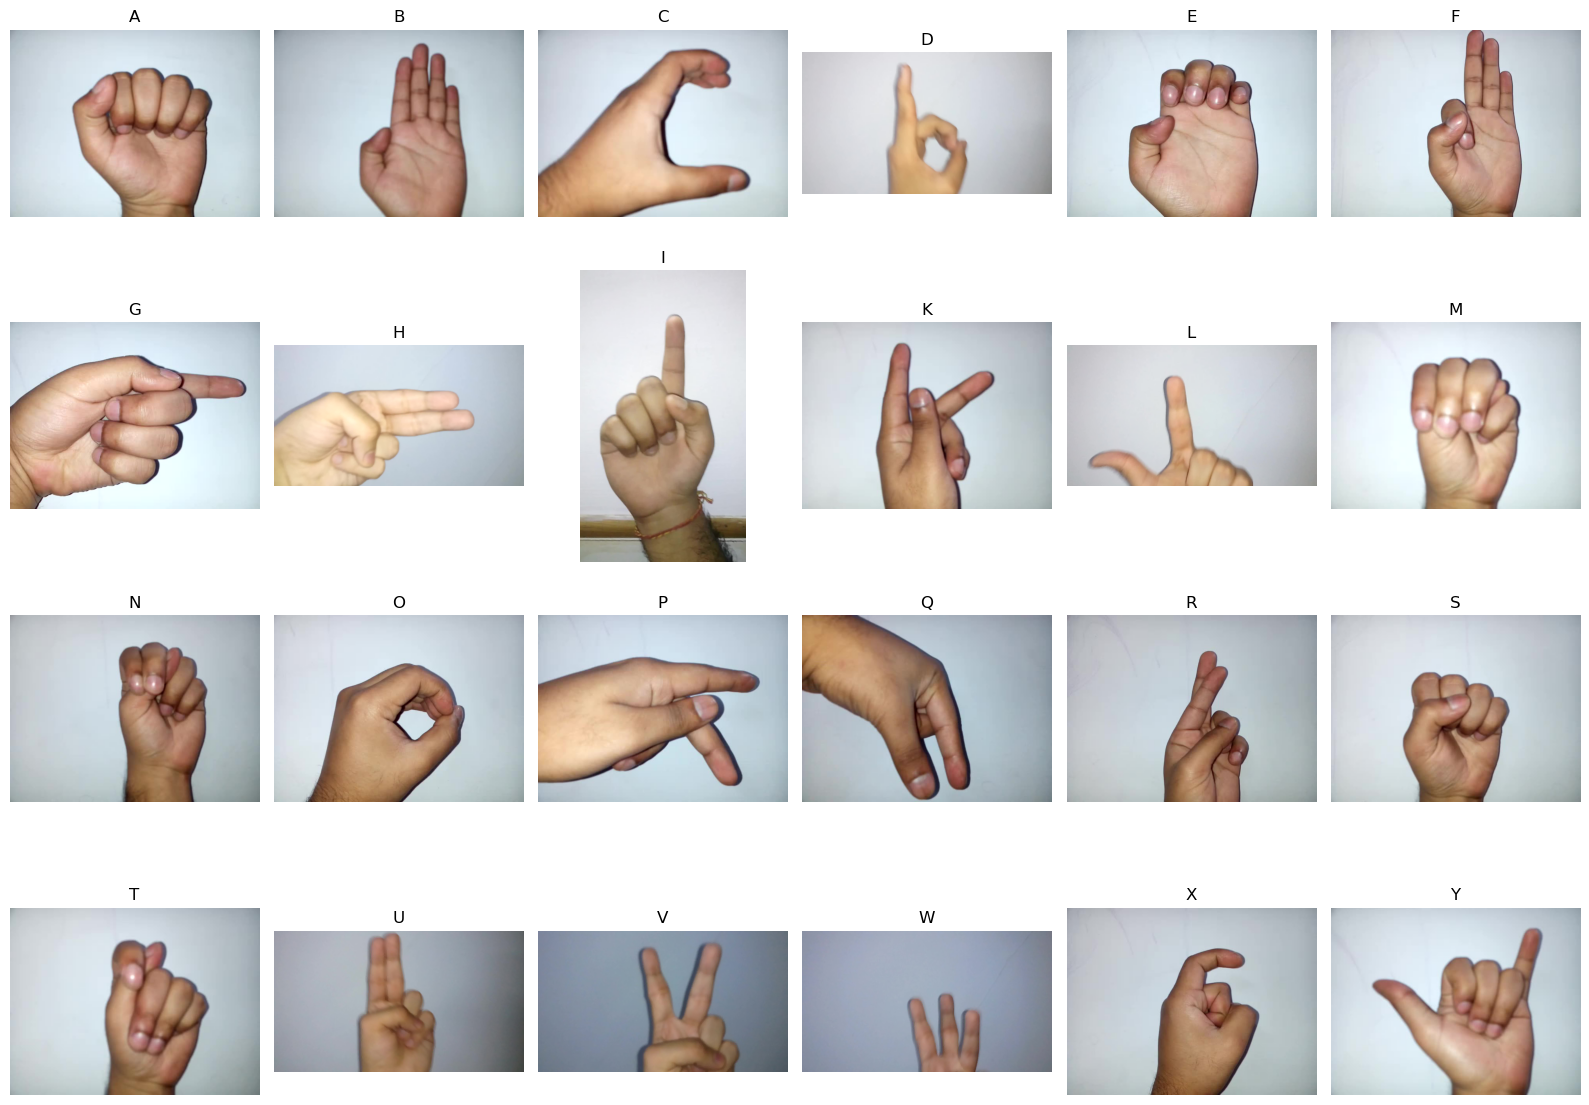

In [8]:
from PIL import Image

# Create a figure
plt.figure(figsize=(16, 12))

# Display one image from each category
for i, category in enumerate(classes):

    folder_path = os.path.join(data_path, category)

    images = sorted([
        file for file in os.listdir(folder_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    image_path = os.path.join(folder_path, images[0])

    image = Image.open(image_path)

    plt.subplot(4, 6, i + 1)
    plt.imshow(image)
    plt.title(category)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
# Check sample image dimensions

for category in classes:

    folder_path = os.path.join(data_path, category)

    images = sorted([
        file for file in os.listdir(folder_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    image_path = os.path.join(folder_path, images[0])

    with Image.open(image_path) as image:
        print(f"{category}: {image.size}")

A: (640, 480)
B: (640, 480)
C: (640, 480)
D: (1920, 1088)
E: (640, 480)
F: (640, 480)
G: (640, 480)
H: (1920, 1088)
I: (1088, 1920)
K: (640, 480)
L: (1920, 1088)
M: (640, 480)
N: (640, 480)
O: (640, 480)
P: (640, 480)
Q: (640, 480)
R: (640, 480)
S: (640, 480)
T: (640, 480)
U: (1920, 1088)
V: (1920, 1088)
W: (1920, 1088)
X: (640, 480)
Y: (640, 480)


In [10]:
# Check image color formats

for category in classes:

    folder_path = os.path.join(data_path, category)

    images = sorted([
        file for file in os.listdir(folder_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    image_path = os.path.join(folder_path, images[0])

    with Image.open(image_path) as image:
        print(f"{category}: {image.mode}")

A: RGB
B: RGB
C: RGB
D: RGB
E: RGB
F: RGB
G: RGB
H: RGB
I: RGB
K: RGB
L: RGB
M: RGB
N: RGB
O: RGB
P: RGB
Q: RGB
R: RGB
S: RGB
T: RGB
U: RGB
V: RGB
W: RGB
X: RGB
Y: RGB


In [11]:
# Check for corrupted images

corrupted_images = []

for category in classes:
    folder_path = os.path.join(data_path, category)

    for file in os.listdir(folder_path):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_path = os.path.join(folder_path, file)

            try:
                with Image.open(image_path) as image:
                    image.load()

            except Exception:
                corrupted_images.append(image_path)

print("Total corrupted images:", len(corrupted_images))

Total corrupted images: 0


### Image Quality and Dataset Analysis

- The dataset contains 4,972 images across 24 sign categories.
- All 24 sample images are in RGB color format.
- Sample images have different dimensions and orientations.
- Some images contain motion blur.
- Most inspected images have light-colored backgrounds.
- Some hand gestures have similar visual characteristics.
- No corrupted images were detected during validation.
- Image resizing and normalization are required before model training.

In [12]:
# Define image dimensions
IMG_HEIGHT = 128
IMG_WIDTH = 128
CHANNELS = 3

print("Target image shape:", 
      (IMG_HEIGHT, IMG_WIDTH, CHANNELS))

Target image shape: (128, 128, 3)


Original Size: (640, 480)
Resized Size: (128, 128)


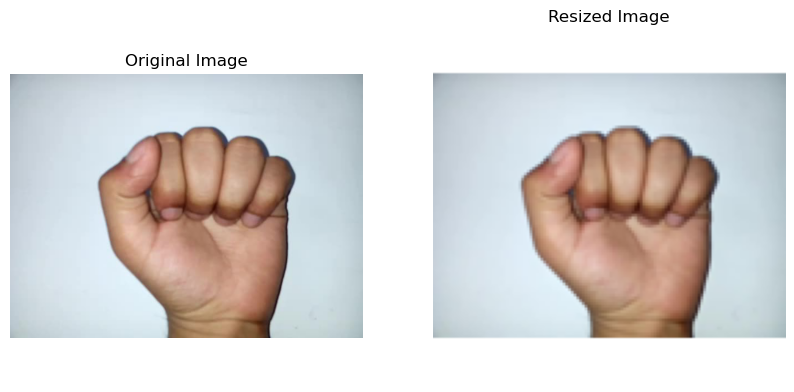

In [13]:
from PIL import ImageOps

# Select a sample image
sample_folder = os.path.join(data_path, "A")

sample_file = sorted([
    file for file in os.listdir(sample_folder)
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
])[0]

sample_path = os.path.join(sample_folder, sample_file)

# Open the original image
original_image = Image.open(sample_path).convert("RGB")

# Resize the image without stretching
resized_image = ImageOps.pad(
    original_image,
    (IMG_WIDTH, IMG_HEIGHT),
    color=(255, 255, 255)
)

# Display image dimensions
print("Original Size:", original_image.size)
print("Resized Size:", resized_image.size)

# Display both images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_image)
plt.title("Resized Image")
plt.axis("off")

plt.show()

In [14]:
import numpy as np

# Convert the resized image into a NumPy array
image_array = np.array(resized_image)

# Normalize pixel values
normalized_image = image_array.astype("float32") / 255.0

# Display results
print("Image Shape:", normalized_image.shape)

print("Before Normalization:")
print("Minimum:", image_array.min())
print("Maximum:", image_array.max())

print("After Normalization:")
print("Minimum:", normalized_image.min())
print("Maximum:", normalized_image.max())

Image Shape: (128, 128, 3)
Before Normalization:
Minimum: 7
Maximum: 255
After Normalization:
Minimum: 0.02745098
Maximum: 1.0


In [15]:
# Create an image preprocessing function

def preprocess_image(image_path):

    with Image.open(image_path) as image:

        # Convert image to RGB
        image = image.convert("RGB")

        # Resize without distortion
        image = ImageOps.pad(
            image,
            (IMG_WIDTH, IMG_HEIGHT),
            color=(255, 255, 255)
        )

        # Convert to NumPy array and normalize
        image = np.array(image, dtype=np.float32) / 255.0

    return image


# Test the preprocessing function
processed_image = preprocess_image(sample_path)

print("Processed Image Shape:", processed_image.shape)
print("Minimum Pixel Value:", processed_image.min())
print("Maximum Pixel Value:", processed_image.max())

Processed Image Shape: (128, 128, 3)
Minimum Pixel Value: 0.02745098
Maximum Pixel Value: 1.0


In [16]:
# Create lists for image paths and labels
image_paths = []
labels = []

# Collect all image paths and labels
for category in classes:

    folder_path = os.path.join(data_path, category)

    for file in sorted(os.listdir(folder_path)):

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_path = os.path.join(folder_path, file)

            image_paths.append(image_path)
            labels.append(category)

# Display results
print("Total Image Paths:", len(image_paths))
print("Total Labels:", len(labels))

print("First Image Path:", image_paths[0])
print("First Image Label:", labels[0])

Total Image Paths: 4972
Total Labels: 4972
First Image Path: ISL_Dataset\Data\A\001.jpg
First Image Label: A


In [17]:
from sklearn.preprocessing import LabelEncoder

# Create the label encoder
label_encoder = LabelEncoder()

# Convert alphabet labels into numbers
encoded_labels = label_encoder.fit_transform(labels)

# Display the class mapping
for index, category in enumerate(label_encoder.classes_):
    print(f"{category} -> {index}")

# Display label information
print("Total Encoded Labels:", len(encoded_labels))
print("First 10 Encoded Labels:", encoded_labels[:10])

A -> 0
B -> 1
C -> 2
D -> 3
E -> 4
F -> 5
G -> 6
H -> 7
I -> 8
K -> 9
L -> 10
M -> 11
N -> 12
O -> 13
P -> 14
Q -> 15
R -> 16
S -> 17
T -> 18
U -> 19
V -> 20
W -> 21
X -> 22
Y -> 23
Total Encoded Labels: 4972
First 10 Encoded Labels: [0 0 0 0 0 0 0 0 0 0]


In [18]:
import pandas as pd

# Create a dataset DataFrame
df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels,
    "encoded_label": encoded_labels
})

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display first five records
display(df.head())

Dataset Shape: (4972, 3)


,image_path,label,encoded_label
0,ISL_Dataset\Data\A\001.jpg,A,0
1,ISL_Dataset\Data\A\002.jpg,A,0
2,ISL_Dataset\Data\A\003.jpg,A,0
3,ISL_Dataset\Data\A\004.jpg,A,0
4,ISL_Dataset\Data\A\005.jpg,A,0


In [19]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check duplicate image paths
print("Duplicate Image Paths:",
      df["image_path"].duplicated().sum())

Missing Values:
image_path       0
label            0
encoded_label    0
dtype: int64

Duplicate Records: 0
Duplicate Image Paths: 0


In [20]:
import hashlib

# Function to generate an image file hash
def get_image_hash(image_path):
    with open(image_path, "rb") as file:
        return hashlib.sha256(file.read()).hexdigest()

# Generate hashes for all images
df["image_hash"] = df["image_path"].apply(get_image_hash)

# Count duplicate image files
duplicate_images = df["image_hash"].duplicated().sum()

print("Total Images:", len(df))
print("Unique Images:", df["image_hash"].nunique())
print("Duplicate Images:", duplicate_images)

Total Images: 4972
Unique Images: 4971
Duplicate Images: 1


In [21]:
# Identify duplicate image files
duplicate_records = df[
    df["image_hash"].duplicated(keep=False)
]

# Display duplicate image details
display(
    duplicate_records[
        ["image_path", "label", "encoded_label"]
    ]
)

print("Total Matching Records:", len(duplicate_records))

,image_path,label,encoded_label
1721,ISL_Dataset\Data\I\001.jpg,I,8
1722,ISL_Dataset\Data\I\002.jpg,I,8


Total Matching Records: 2


In [22]:
# Count images before removing duplicates
print("Before Removing Duplicates:", len(df))

# Remove duplicate image records
df = df.drop_duplicates(
    subset="image_hash",
    keep="first"
).reset_index(drop=True)

# Display results
print("After Removing Duplicates:", len(df))
print("Remaining Duplicates:", df["image_hash"].duplicated().sum())
print("Total Classes:", df["label"].nunique())
print("Dataset Shape:", df.shape)

Before Removing Duplicates: 4972
After Removing Duplicates: 4971
Remaining Duplicates: 0
Total Classes: 24
Dataset Shape: (4971, 4)


In [23]:
# Inspect image filenames for each category

for category in classes:

    category_images = df[df["label"] == category]

    filenames = category_images["image_path"].apply(
        os.path.basename
    )

    print(f"{category}: {filenames.head(5).tolist()}")

A: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
B: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
C: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
D: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
E: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
F: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
G: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
H: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
I: ['001.jpg', '003.jpg', '004.jpg', '005.jpg', '006.jpg']
K: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
L: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
M: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
N: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
O: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
P: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
Q: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg']
R: ['001.jpg', '002.jpg', '003.jpg', '004.jpg', '005.jpg

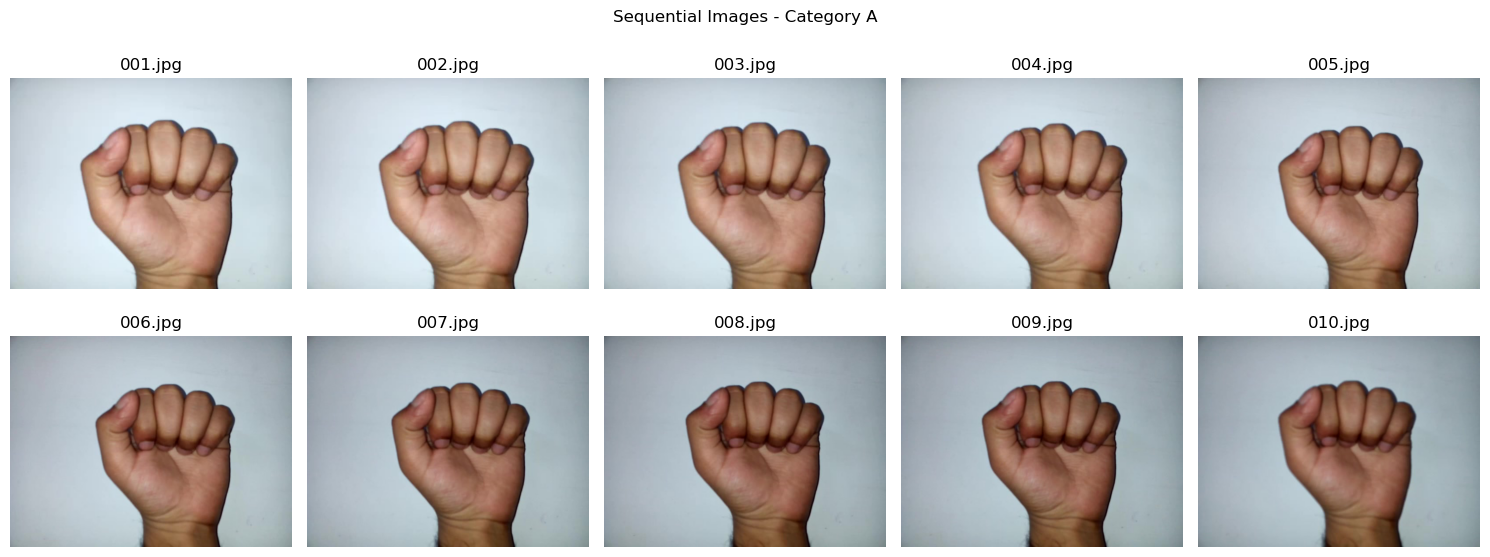

In [24]:
# Select the first 10 images from category A
sample_images = df[df["label"] == "A"].head(10)

# Create a visualization
plt.figure(figsize=(15, 6))

for i, path in enumerate(sample_images["image_path"]):

    with Image.open(path) as image:

        plt.subplot(2, 5, i + 1)
        plt.imshow(image.convert("RGB"))
        plt.title(os.path.basename(path))
        plt.axis("off")

plt.suptitle("Sequential Images - Category A")
plt.tight_layout()
plt.show()

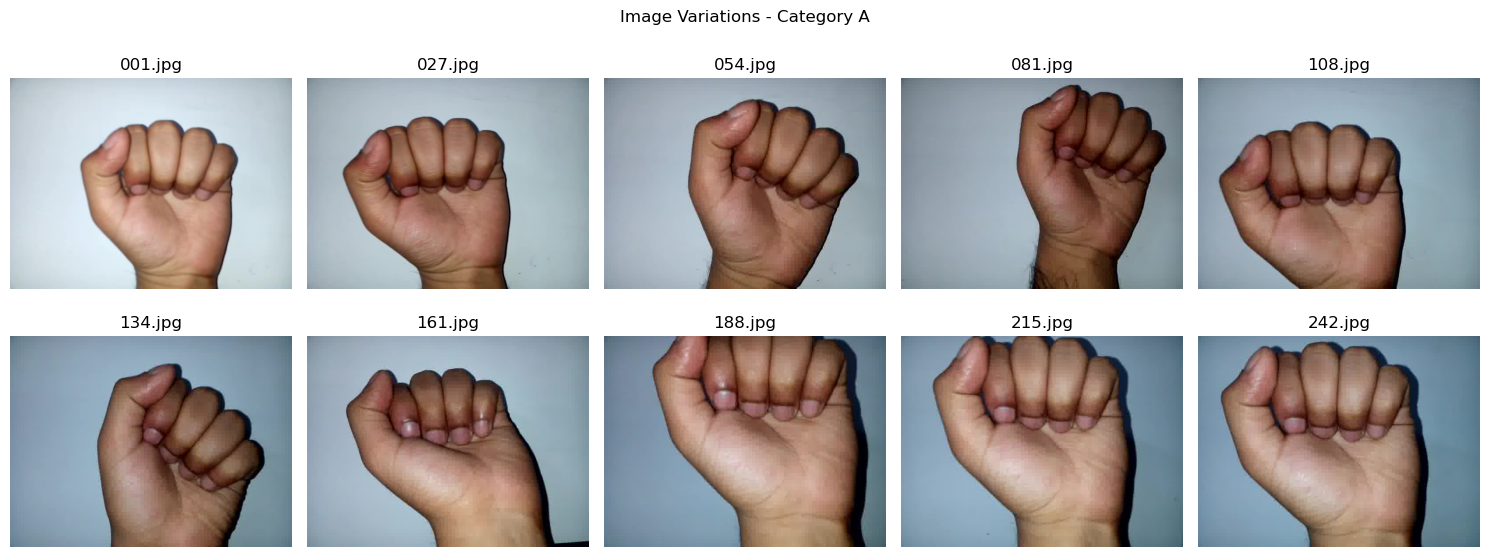

In [25]:
# Select all images from category A
category_images = df[df["label"] == "A"]

# Select 10 evenly spaced images
indices = np.linspace(
    0, len(category_images) - 1, 10, dtype=int
)

sample_images = category_images.iloc[indices]

# Display selected images
plt.figure(figsize=(15, 6))

for i, path in enumerate(sample_images["image_path"]):

    with Image.open(path) as image:

        plt.subplot(2, 5, i + 1)
        plt.imshow(image.convert("RGB"))
        plt.title(os.path.basename(path))
        plt.axis("off")

plt.suptitle("Image Variations - Category A")
plt.tight_layout()
plt.show()

### Dataset Similarity and Data Leakage Analysis

- The original dataset contains 4,972 images.
- One exact duplicate image was identified and excluded.
- The cleaned dataset contains 4,971 images across 24 classes.
- Most images follow sequential filename patterns.
- Consecutive images show high visual similarity.
- Variations in hand orientation, position and lighting were observed.
- Background diversity appears limited in the inspected images.
- Random dataset splitting may introduce data leakage.
- Recording-session information is not available in the current DataFrame.
- A careful dataset splitting strategy is required for reliable model evaluation.

In [26]:
# Define dataset split ratios

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# Display split configuration
print("Total Images:", len(df))
print("Training Ratio:", TRAIN_RATIO)
print("Validation Ratio:", VAL_RATIO)
print("Testing Ratio:", TEST_RATIO)

print("Total Ratio:",
      TRAIN_RATIO + VAL_RATIO + TEST_RATIO)

Total Images: 4971
Training Ratio: 0.7
Validation Ratio: 0.15
Testing Ratio: 0.15
Total Ratio: 1.0


In [27]:
# Create lists for dataset subsets
train_parts = []
val_parts = []
test_parts = []

# Split each category separately
for category in classes:

    category_df = df[df["label"] == category].sort_values(
        "image_path"
    )

    n = len(category_df)

    train_end = int(n * TRAIN_RATIO)
    val_end = train_end + int(n * VAL_RATIO)

    train_parts.append(category_df.iloc[:train_end])
    val_parts.append(category_df.iloc[train_end:val_end])
    test_parts.append(category_df.iloc[val_end:])

# Combine all categories
train_df = pd.concat(train_parts).reset_index(drop=True)
val_df = pd.concat(val_parts).reset_index(drop=True)
test_df = pd.concat(test_parts).reset_index(drop=True)

# Display dataset sizes
print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))

print("Total Images:",
      len(train_df) + len(val_df) + len(test_df))

Training Images: 3468
Validation Images: 736
Testing Images: 767
Total Images: 4971


In [28]:
# Check class coverage
print("Training Classes:", train_df["label"].nunique())
print("Validation Classes:", val_df["label"].nunique())
print("Testing Classes:", test_df["label"].nunique())

# Create sets of image hashes
train_hashes = set(train_df["image_hash"])
val_hashes = set(val_df["image_hash"])
test_hashes = set(test_df["image_hash"])

# Check overlapping images
print("\nTraining-Validation Overlap:",
      len(train_hashes & val_hashes))

print("Training-Testing Overlap:",
      len(train_hashes & test_hashes))

print("Validation-Testing Overlap:",
      len(val_hashes & test_hashes))

# Check total unique images
print("\nTotal Unique Images:",
      len(train_hashes | val_hashes | test_hashes))

Training Classes: 24
Validation Classes: 24
Testing Classes: 24

Training-Validation Overlap: 0
Training-Testing Overlap: 0
Validation-Testing Overlap: 0

Total Unique Images: 4971


In [29]:
# Calculate class distribution for each dataset
split_distribution = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
}).sort_index()

# Calculate total images per category
split_distribution["Total"] = split_distribution.sum(axis=1)

# Display class distribution
display(split_distribution)

# Display dataset totals
print("\nDataset Totals:")
print(split_distribution.sum())

,Training,Validation,Testing,Total
label,,,,
A,169,36,37,242
B,181,38,40,259
C,172,37,38,247
D,102,22,23,147
E,170,36,37,243
F,158,33,35,226
G,168,36,37,241
H,81,17,18,116
I,124,26,28,178



Dataset Totals:
Training      3468
Validation     736
Testing        767
Total         4971
dtype: int64


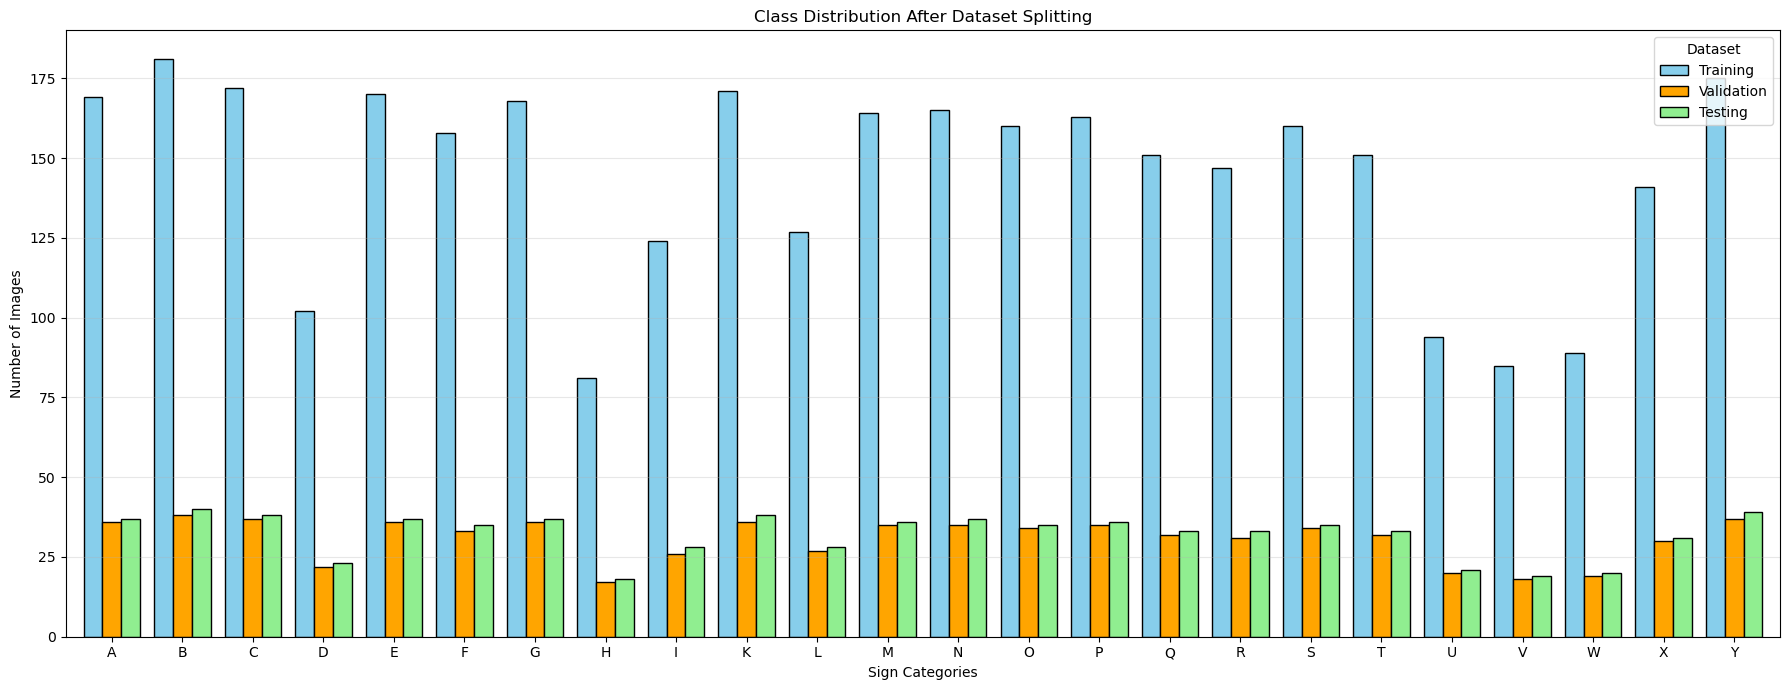

In [30]:
# Visualize class distribution after splitting

split_distribution[
    ["Training", "Validation", "Testing"]
].plot(
    kind="bar",
    figsize=(18, 7),
    color=["skyblue", "orange", "lightgreen"],
    edgecolor="black",
    width=0.8
)

plt.title("Class Distribution After Dataset Splitting")
plt.xlabel("Sign Categories")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
from sklearn.utils.class_weight import compute_class_weight

# Calculate class weights using training labels
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["encoded_label"]),
    y=train_df["encoded_label"]
)

# Convert weights into a dictionary
class_weight_dict = dict(
    zip(np.unique(train_df["encoded_label"]), class_weights)
)

# Display class weights
for index, weight in class_weight_dict.items():
    print(f"{label_encoder.classes_[index]}: {weight:.4f}")

print("\nTotal Class Weights:", len(class_weight_dict))

A: 0.8550
B: 0.7983
C: 0.8401
D: 1.4167
E: 0.8500
F: 0.9146
G: 0.8601
H: 1.7840
I: 1.1653
K: 0.8450
L: 1.1378
M: 0.8811
N: 0.8758
O: 0.9031
P: 0.8865
Q: 0.9570
R: 0.9830
S: 0.9031
T: 0.9570
U: 1.5372
V: 1.7000
W: 1.6236
X: 1.0248
Y: 0.8257

Total Class Weights: 24


In [33]:
# Import TensorFlow
import tensorflow as tf

# Check TensorFlow version
print("TensorFlow Version:", tf.__version__)

# Check GPU availability
gpus = tf.config.list_physical_devices("GPU")

print("Available GPUs:", len(gpus))

# Display GPU status
if len(gpus) > 0:
    print("GPU is available")
else:
    print("Training will use CPU")

TensorFlow Version: 2.21.0
Available GPUs: 0
Training will use CPU


In [34]:
# Configure model training parameters

BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 0.001
NUM_CLASSES = len(classes)
SEED = 42

# Set random seed
tf.keras.utils.set_random_seed(SEED)

# Display configuration
print("Image Height:", IMG_HEIGHT)
print("Image Width:", IMG_WIDTH)
print("Channels:", CHANNELS)
print("Batch Size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)
print("Number of Classes:", NUM_CLASSES)
print("Random Seed:", SEED)

Image Height: 128
Image Width: 128
Channels: 3
Batch Size: 32
Epochs: 20
Learning Rate: 0.001
Number of Classes: 24
Random Seed: 42


In [35]:
# Function to create TensorFlow datasets

def create_dataset(dataframe):

    paths = dataframe["image_path"].astype(str).tolist()

    targets = dataframe["encoded_label"].to_numpy(
        dtype=np.int32
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, targets)
    )

    return dataset


# Create training, validation and testing datasets
train_ds = create_dataset(train_df)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

# Display dataset information
print("Training Dataset:", len(train_ds))
print("Validation Dataset:", len(val_ds))
print("Testing Dataset:", len(test_ds))

print("\nDataset Structure:")
print(train_ds.element_spec)

Training Dataset: 3468
Validation Dataset: 736
Testing Dataset: 767

Dataset Structure:
(TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))


In [36]:
# Create TensorFlow image preprocessing function

def tf_preprocess_image(image_path, label):

    # Read the image file
    image = tf.io.read_file(image_path)

    # Decode image into RGB format
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Normalize pixel values
    image = tf.cast(image, tf.float32) / 255.0

    # Resize with white padding
    image = 1.0 - tf.image.resize_with_pad(
        1.0 - image,
        IMG_HEIGHT,
        IMG_WIDTH
    )

    # Set image shape
    image.set_shape(
        (IMG_HEIGHT, IMG_WIDTH, CHANNELS)
    )

    return image, label


# Test preprocessing on one image
for path, label in train_ds.take(1):

    image, label = tf_preprocess_image(path, label)

    print("Image Shape:", image.shape)
    print("Data Type:", image.dtype)
    print("Minimum Pixel:", tf.reduce_min(image).numpy())
    print("Maximum Pixel:", tf.reduce_max(image).numpy())
    print("Encoded Label:", label.numpy())

Image Shape: (128, 128, 3)
Data Type: <dtype: 'float32'>
Minimum Pixel: 0.0
Maximum Pixel: 1.0
Encoded Label: 0


In [37]:
# Apply preprocessing to all datasets

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.map(
    tf_preprocess_image,
    num_parallel_calls=AUTOTUNE
)

val_ds = val_ds.map(
    tf_preprocess_image,
    num_parallel_calls=AUTOTUNE
)

test_ds = test_ds.map(
    tf_preprocess_image,
    num_parallel_calls=AUTOTUNE
)

# Display dataset structure
print("Training Dataset:", train_ds.element_spec)
print("\nValidation Dataset:", val_ds.element_spec)
print("\nTesting Dataset:", test_ds.element_spec)

Training Dataset: (TensorSpec(shape=(128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))

Validation Dataset: (TensorSpec(shape=(128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))

Testing Dataset: (TensorSpec(shape=(128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))


In [38]:
# Shuffle training paths before image preprocessing
train_ds = create_dataset(train_df)

train_ds = train_ds.shuffle(
    buffer_size=len(train_df),
    seed=SEED,
    reshuffle_each_iteration=True
)

train_ds = train_ds.map(
    tf_preprocess_image,
    num_parallel_calls=AUTOTUNE
)

# Batch and prefetch all datasets
train_ds = train_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = val_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

test_ds = test_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

# Display batch information
print("Training Batches:", len(train_ds))
print("Validation Batches:", len(val_ds))
print("Testing Batches:", len(test_ds))

# Inspect one training batch
for images, targets in train_ds.take(1):
    print("\nBatch Image Shape:", images.shape)
    print("Batch Label Shape:", targets.shape)

Training Batches: 109
Validation Batches: 23
Testing Batches: 24

Batch Image Shape: (32, 128, 128, 3)
Batch Label Shape: (32,)


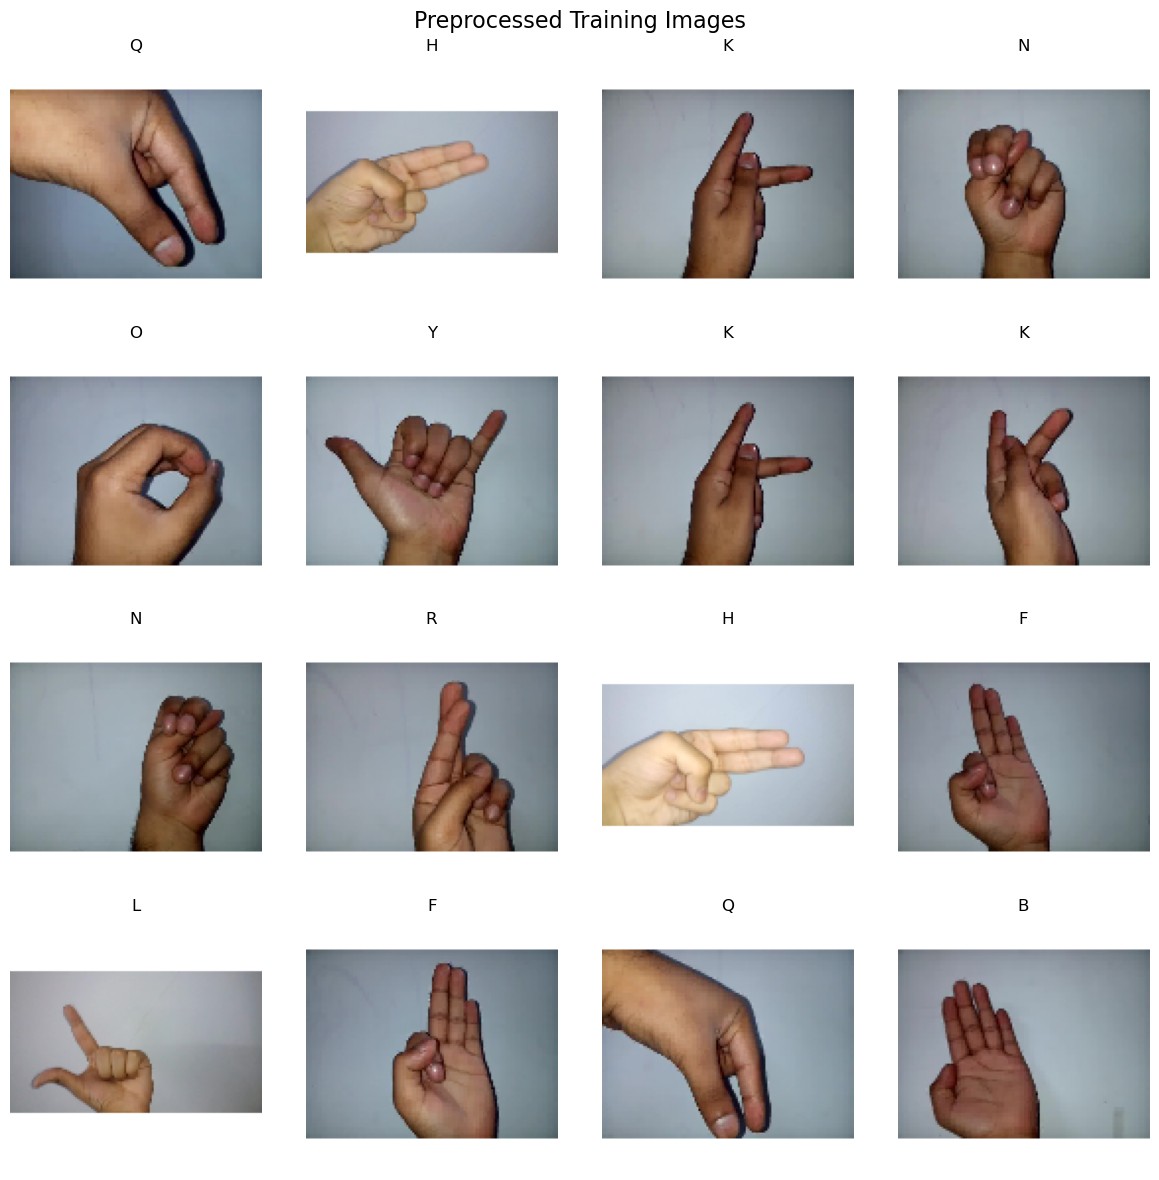

In [39]:
# Visualize preprocessed training images

plt.figure(figsize=(12, 12))

for images, targets in train_ds.take(1):

    for i in range(16):

        plt.subplot(4, 4, i + 1)

        plt.imshow(images[i].numpy())

        label_index = targets[i].numpy()

        plt.title(
            label_encoder.classes_[label_index]
        )

        plt.axis("off")

plt.suptitle("Preprocessed Training Images", fontsize=16)
plt.tight_layout()
plt.show()

In [40]:
from tensorflow.keras import layers

# Create data augmentation layers
data_augmentation = tf.keras.Sequential([

    layers.RandomRotation(
        0.05, fill_mode="constant", fill_value=1.0
    ),

    layers.RandomZoom(
        0.10, fill_mode="constant", fill_value=1.0
    ),

    layers.RandomTranslation(
        0.05, 0.05,
        fill_mode="constant", fill_value=1.0
    ),

    layers.RandomContrast(0.10)

], name="data_augmentation")

# Display augmentation configuration
print("Data Augmentation Created Successfully")

for layer in data_augmentation.layers:
    print(layer.__class__.__name__)

Data Augmentation Created Successfully
RandomRotation
RandomZoom
RandomTranslation
RandomContrast


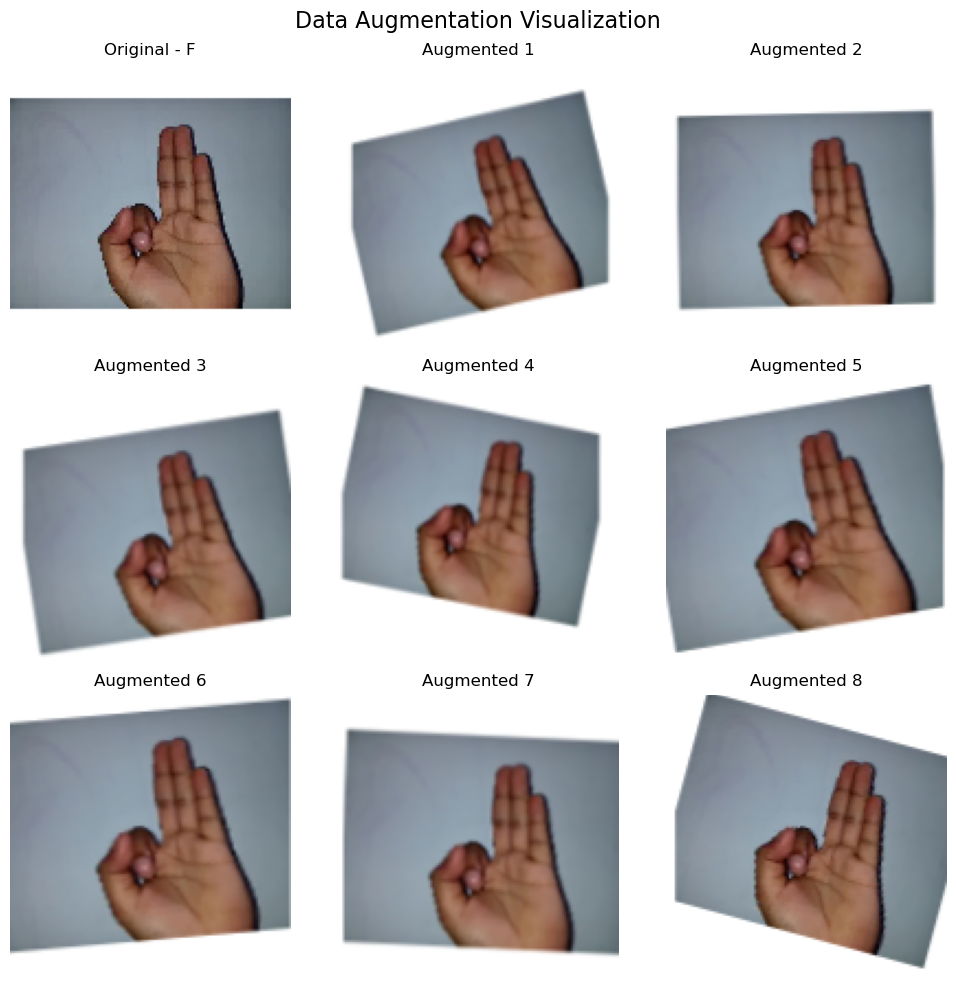

In [41]:
# Select one training image
for images, targets in train_ds.take(1):

    original_image = images[0]
    original_label = targets[0].numpy()

# Create visualization
plt.figure(figsize=(10, 10))

# Display original image
plt.subplot(3, 3, 1)
plt.imshow(original_image.numpy())
plt.title(
    f"Original - {label_encoder.classes_[original_label]}"
)
plt.axis("off")

# Generate and display augmented images
for i in range(8):

    augmented_image = data_augmentation(
        tf.expand_dims(original_image, 0),
        training=True
    )

    plt.subplot(3, 3, i + 2)

    plt.imshow(
        tf.clip_by_value(augmented_image[0], 0, 1).numpy()
    )

    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.suptitle("Data Augmentation Visualization", fontsize=16)
plt.tight_layout()
plt.show()

In [42]:
# Build CNN model architecture

model = tf.keras.Sequential([

    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)),

    # Data augmentation
    data_augmentation,

    # First convolutional block
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.3),

    # Output layer
    layers.Dense(NUM_CLASSES, activation="softmax")

], name="ISL_CNN_Model")

print("CNN Model Created Successfully")

model.summary()

CNN Model Created Successfully


Model: "ISL_CNN_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)       │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 24)                  │           3,096 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 112,856 (440.84 KB)

 Trainable params: 112,856 (440.84 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
# Compile the CNN model

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

# Display compilation information
print("CNN Model Compiled Successfully")
print("Optimizer: Adam")
print("Learning Rate:", LEARNING_RATE)
print("Loss Function: Sparse Categorical Crossentropy")
print("Evaluation Metric: Accuracy")

CNN Model Compiled Successfully
Optimizer: Adam
Learning Rate: 0.001
Loss Function: Sparse Categorical Crossentropy
Evaluation Metric: Accuracy


In [44]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Early stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Reduce learning rate
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.000001,
    verbose=1
)

# Save the best model
checkpoint = ModelCheckpoint(
    "best_isl_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Combine all callbacks
callbacks = [
    early_stopping,
    reduce_lr,
    checkpoint
]

print("Callbacks Created Successfully")

for callback in callbacks:
    print(callback.__class__.__name__)

Callbacks Created Successfully
EarlyStopping
ReduceLROnPlateau
ModelCheckpoint


In [45]:
# Train the CNN model

history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS,

    class_weight=class_weight_dict,

    callbacks=callbacks,

    verbose=1

)

print("\nCNN Model Training Completed Successfully!")

Epoch 1/20


C:\Users\vamsi\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.0484 - loss: 3.1391
Epoch 1: val_loss improved from None to 2.88466, saving model to best_isl_model.keras

Epoch 1: finished saving model to best_isl_model.keras
109/109 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - accuracy: 0.0484 - loss: 3.1391 - val_accuracy: 0.0774 - val_loss: 2.8847 - learning_rate: 0.0010
Epoch 2/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.1024 - loss: 2.7159
Epoch 2: val_loss improved from 2.88466 to 2.56695, saving model to best_isl_model.keras

Epoch 2: finished saving model to best_isl_model.keras
109/109 ━━━━━━━━━━━━━━━━━━━━ 162s 1s/step - accuracy: 0.1024 - loss: 2.7159 - val_accuracy: 0.1454 - val_loss: 2.5669 - learning_rate: 0.0010
Epoch 3/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 759ms/step - accuracy: 0.1220 - loss: 2.5892
Epoch 3: val_loss improved from 2.56695 to 2.53107, saving model to best_isl_model.keras

Epoch 3: finished saving model to best_isl_model.keras
109/109 ━━━━━━━━━━━━━━━━━━━━ 231s 2s/

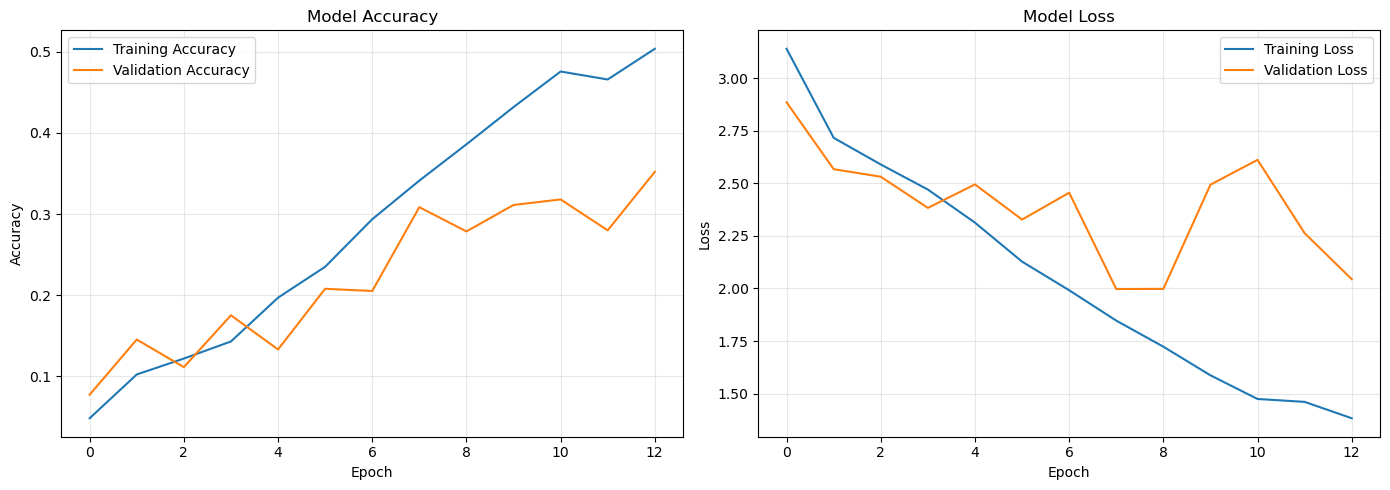

In [46]:
# Plot training and validation performance

plt.figure(figsize=(14, 5))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

# Loss graph
plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [47]:
# Load the best baseline CNN model
baseline_model = tf.keras.models.load_model(
    "best_isl_model.keras"
)

# Evaluate on validation data
baseline_val_loss, baseline_val_accuracy = (
    baseline_model.evaluate(val_ds, verbose=1)
)

# Display results
print("\nBaseline CNN Results")
print("Validation Loss:", round(baseline_val_loss, 4))
print("Validation Accuracy:",
      round(baseline_val_accuracy * 100, 2), "%")

23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 0.3084 - loss: 1.9973

Baseline CNN Results
Validation Loss: 1.9973
Validation Accuracy: 30.84 %


## Baseline CNN Model Analysis

The custom CNN model was trained to classify
24 sign language gesture classes.

### Model Performance

- Total parameters: 112,856
- Maximum epochs: 20
- Completed epochs: 13
- Best epoch: 8
- Final training accuracy: 50.35%
- Highest validation accuracy: 35.19%
- Best saved model validation accuracy: 30.84%
- Best validation loss: 1.9973

### Identified Challenges

- Low validation accuracy.
- Signs of model overfitting.
- Similarities between hand gestures.
- Limited background diversity.
- Moderate class imbalance.
- Limited feature extraction capability.

### Model Improvement Strategy

- Implement transfer learning using MobileNetV2.
- Utilize pretrained ImageNet weights.
- Improve feature extraction.
- Apply appropriate image preprocessing.
- Compare baseline and improved model performance.
- Select the best model using validation results.
- Evaluate the selected model on unseen test data.

In [48]:
from tensorflow.keras.applications import MobileNetV2

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Display model information
print("MobileNetV2 Loaded Successfully")
print("Input Shape:", base_model.input_shape)
print("Output Shape:", base_model.output_shape)
print("Total Parameters:", base_model.count_params())
print("Trainable:", base_model.trainable)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 Loaded Successfully
Input Shape: (None, 128, 128, 3)
Output Shape: (None, 4, 4, 1280)
Total Parameters: 2257984
Trainable: False


In [49]:
# Create MobileNetV2 preprocessing layer

mobilenet_preprocessing = layers.Rescaling(
    scale=2.0,
    offset=-1.0,
    name="mobilenet_preprocessing"
)

# Get a sample batch
sample_images, sample_labels = next(iter(train_ds))

# Apply preprocessing
mobilenet_images = mobilenet_preprocessing(sample_images)

# Display results
print("MobileNetV2 Preprocessing Successful")

print("\nBefore Preprocessing:")
print("Minimum:", tf.reduce_min(sample_images).numpy())
print("Maximum:", tf.reduce_max(sample_images).numpy())

print("\nAfter Preprocessing:")
print("Minimum:", tf.reduce_min(mobilenet_images).numpy())
print("Maximum:", tf.reduce_max(mobilenet_images).numpy())

print("\nOutput Shape:", mobilenet_images.shape)

MobileNetV2 Preprocessing Successful

Before Preprocessing:
Minimum: 0.0
Maximum: 1.0

After Preprocessing:
Minimum: -1.0
Maximum: 1.0

Output Shape: (32, 128, 128, 3)


In [50]:
# Build MobileNetV2 transfer learning model

inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)
)

# Data augmentation
x = data_augmentation(inputs)

# Keep pixel values within 0 and 1
x = layers.ReLU(max_value=1.0)(x)

# MobileNetV2 preprocessing
x = mobilenet_preprocessing(x)

# Pretrained feature extraction
x = base_model(x, training=False)

# Classification layers
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(128, activation="relu")(x)

x = layers.Dropout(0.3)(x)

# Output layer
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

# Create model
transfer_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="ISL_MobileNetV2_Model"
)

print("MobileNetV2 Model Created Successfully")

transfer_model.summary()

MobileNetV2 Model Created Successfully


Model: "ISL_MobileNetV2_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu (ReLU)                         │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenet_preprocessing (Rescaling)  │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_128 (Functional)    │ (None, 4, 4, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 24)                  │           3,096 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,425,048 (9.25 MB)

 Trainable params: 167,064 (652.59 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [51]:
# Compile MobileNetV2 transfer learning model

TRANSFER_LEARNING_RATE = 0.001

transfer_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=TRANSFER_LEARNING_RATE
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("MobileNetV2 Model Compiled Successfully")
print("Optimizer: Adam")
print("Learning Rate:", TRANSFER_LEARNING_RATE)
print("Loss Function: Sparse Categorical Crossentropy")
print("Evaluation Metric: Accuracy")

MobileNetV2 Model Compiled Successfully
Optimizer: Adam
Learning Rate: 0.001
Loss Function: Sparse Categorical Crossentropy
Evaluation Metric: Accuracy


In [52]:
# Early stopping
transfer_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Reduce learning rate
transfer_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.000001,
    verbose=1
)

# Save the best MobileNetV2 model
transfer_checkpoint = ModelCheckpoint(
    "best_mobilenetv2_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Combine callbacks
transfer_callbacks = [
    transfer_early_stopping,
    transfer_reduce_lr,
    transfer_checkpoint
]

print("MobileNetV2 Callbacks Created Successfully")

for callback in transfer_callbacks:
    print(callback.__class__.__name__)

MobileNetV2 Callbacks Created Successfully
EarlyStopping
ReduceLROnPlateau
ModelCheckpoint


In [54]:
# Train MobileNetV2 transfer learning model

transfer_history = transfer_model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS,

    class_weight=class_weight_dict,

    callbacks=transfer_callbacks,

    shuffle=False,

    verbose=1

)

print("\nMobileNetV2 Model Training Completed Successfully!")

Epoch 1/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 328ms/step - accuracy: 0.6929 - loss: 1.1105
Epoch 1: val_loss improved from None to 0.29705, saving model to best_mobilenetv2_model.keras

Epoch 1: finished saving model to best_mobilenetv2_model.keras
109/109 ━━━━━━━━━━━━━━━━━━━━ 54s 412ms/step - accuracy: 0.6929 - loss: 1.1105 - val_accuracy: 0.9198 - val_loss: 0.2971 - learning_rate: 0.0010
Epoch 2/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 263ms/step - accuracy: 0.9308 - loss: 0.2462
Epoch 2: val_loss improved from 0.29705 to 0.13776, saving model to best_mobilenetv2_model.keras

Epoch 2: finished saving model to best_mobilenetv2_model.keras
109/109 ━━━━━━━━━━━━━━━━━━━━ 72s 323ms/step - accuracy: 0.9308 - loss: 0.2462 - val_accuracy: 0.9755 - val_loss: 0.1378 - learning_rate: 0.0010
Epoch 3/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.9637 - loss: 0.1411
Epoch 3: val_loss improved from 0.13776 to 0.09383, saving model to best_mobilenetv2_model.keras

Epoch 3: finished saving model 

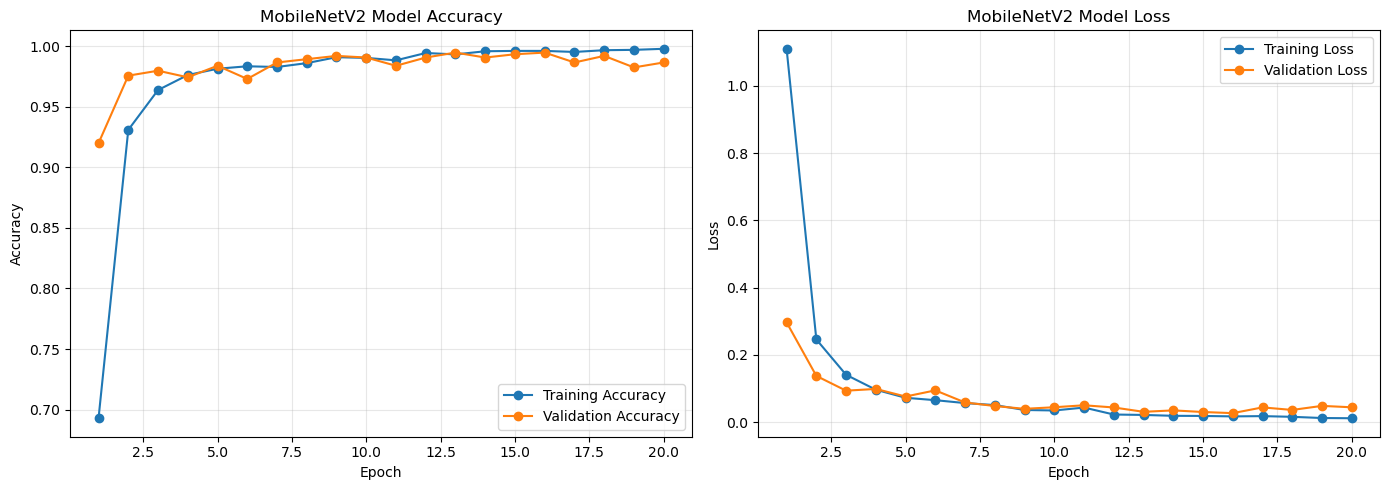

In [55]:
# Visualize MobileNetV2 training performance

transfer_epochs = range(
    1, len(transfer_history.history["accuracy"]) + 1
)

plt.figure(figsize=(14, 5))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(
    transfer_epochs,
    transfer_history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    transfer_epochs,
    transfer_history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("MobileNetV2 Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

# Loss graph
plt.subplot(1, 2, 2)

plt.plot(
    transfer_epochs,
    transfer_history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    transfer_epochs,
    transfer_history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("MobileNetV2 Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [56]:
# Load the best MobileNetV2 model

best_transfer_model = tf.keras.models.load_model(
    "best_mobilenetv2_model.keras"
)

# Evaluate on validation dataset

transfer_val_loss, transfer_val_accuracy = (
    best_transfer_model.evaluate(val_ds, verbose=1)
)

# Display evaluation results

print("\nMobileNetV2 Evaluation Results")

print("Validation Loss:",
      round(transfer_val_loss, 4))

print("Validation Accuracy:",
      round(transfer_val_accuracy * 100, 2), "%")

23/23 ━━━━━━━━━━━━━━━━━━━━ 20s 597ms/step - accuracy: 0.9946 - loss: 0.0271

MobileNetV2 Evaluation Results
Validation Loss: 0.0271
Validation Accuracy: 99.46 %


In [57]:
# Compare model performance

model_comparison = pd.DataFrame({

    "Model": [
        "Baseline CNN",
        "MobileNetV2"
    ],

    "Validation Accuracy (%)": [
        baseline_val_accuracy * 100,
        transfer_val_accuracy * 100
    ],

    "Validation Loss": [
        baseline_val_loss,
        transfer_val_loss
    ],

    "Total Parameters": [
        baseline_model.count_params(),
        best_transfer_model.count_params()
    ],

    "Best Epoch": [8, 16]

})

display(model_comparison.round(4))

,Model,Validation Accuracy (%),Validation Loss,Total Parameters,Best Epoch
0,Baseline CNN,30.8424,1.9973,112856,8
1,MobileNetV2,99.4565,0.0271,2425048,16


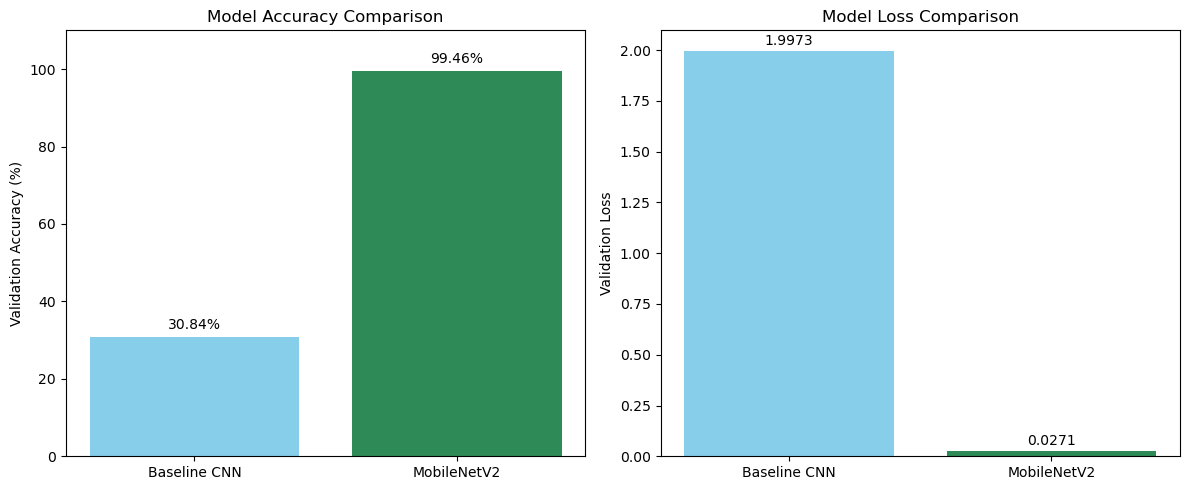

In [58]:
# Visualize model performance comparison

plt.figure(figsize=(12, 5))

# Validation accuracy comparison
plt.subplot(1, 2, 1)

plt.bar(
    model_comparison["Model"],
    model_comparison["Validation Accuracy (%)"],
    color=["skyblue", "seagreen"]
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Validation Accuracy (%)")
plt.ylim(0, 110)

for i, value in enumerate(
    model_comparison["Validation Accuracy (%)"]
):
    plt.text(i, value + 2, f"{value:.2f}%",
             ha="center")

# Validation loss comparison
plt.subplot(1, 2, 2)

plt.bar(
    model_comparison["Model"],
    model_comparison["Validation Loss"],
    color=["skyblue", "seagreen"]
)

plt.title("Model Loss Comparison")
plt.ylabel("Validation Loss")

for i, value in enumerate(
    model_comparison["Validation Loss"]
):
    plt.text(i, value + 0.03, f"{value:.4f}",
             ha="center")

plt.tight_layout()
plt.show()

In [59]:
# Select the best-performing model

final_model = best_transfer_model

final_model_name = "MobileNetV2"

print("Final Model Selected Successfully")

print("Selected Model:", final_model_name)

print("Validation Accuracy:",
      round(transfer_val_accuracy * 100, 2), "%")

print("Validation Loss:",
      round(transfer_val_loss, 4))

print("Total Parameters:",
      final_model.count_params())

print("Number of Classes:", NUM_CLASSES)

print("Test Images:", len(test_df))

Final Model Selected Successfully
Selected Model: MobileNetV2
Validation Accuracy: 99.46 %
Validation Loss: 0.0271
Total Parameters: 2425048
Number of Classes: 24
Test Images: 767


In [60]:
# Evaluate final model on test dataset

test_loss, test_accuracy = final_model.evaluate(
    test_ds,
    verbose=1
)

# Display final test results

print("\nFinal Model Test Results")
print("-" * 40)

print("Model:", final_model_name)

print("Test Images:", len(test_df))

print("Test Loss:", round(test_loss, 4))

print("Test Accuracy:",
      round(test_accuracy * 100, 2), "%")

print("Validation Accuracy:",
      round(transfer_val_accuracy * 100, 2), "%")

print("-" * 40)

24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 331ms/step - accuracy: 0.9465 - loss: 0.1549

Final Model Test Results
----------------------------------------
Model: MobileNetV2
Test Images: 767
Test Loss: 0.1549
Test Accuracy: 94.65 %
Validation Accuracy: 99.46 %
----------------------------------------


In [61]:
# Generate predictions on test dataset

y_pred_prob = final_model.predict(
    test_ds,
    verbose=1
)

# Convert probabilities into predicted class labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Extract actual class labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

# Display prediction information
print("\nPredictions Generated Successfully")

print("Prediction Probability Shape:",
      y_pred_prob.shape)

print("Predicted Labels Shape:", y_pred.shape)

print("Actual Labels Shape:", y_true.shape)

print("\nFirst 10 Actual Labels:", y_true[:10])

print("First 10 Predicted Labels:", y_pred[:10])

print("\nCorrect Predictions:",
      np.sum(y_true == y_pred))

print("Incorrect Predictions:",
      np.sum(y_true != y_pred))

24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 472ms/step

Predictions Generated Successfully
Prediction Probability Shape: (767, 24)
Predicted Labels Shape: (767,)
Actual Labels Shape: (767,)

First 10 Actual Labels: [0 0 0 0 0 0 0 0 0 0]
First 10 Predicted Labels: [0 0 0 0 0 0 0 0 0 0]

Correct Predictions: 726
Incorrect Predictions: 41


In [62]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate evaluation metrics

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

# Display evaluation metrics

print("Final Model Evaluation Metrics")
print("-" * 40)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("-" * 40)

Final Model Evaluation Metrics
----------------------------------------
Accuracy  : 0.9465
Precision : 0.9502
Recall    : 0.9406
F1-Score  : 0.9400
----------------------------------------


In [63]:
from sklearn.metrics import classification_report

# Generate classification report

report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0
)

# Display classification report

print("MobileNetV2 Classification Report")
print("=" * 65)

print(report)

MobileNetV2 Classification Report
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000        37
           B     1.0000    0.8250    0.9041        40
           C     1.0000    1.0000    1.0000        38
           D     1.0000    0.8261    0.9048        23
           E     0.9737    1.0000    0.9867        37
           F     0.7714    0.7714    0.7714        35
           G     1.0000    1.0000    1.0000        37
           H     1.0000    1.0000    1.0000        18
           I     1.0000    1.0000    1.0000        28
           K     1.0000    1.0000    1.0000        38
           L     0.9032    1.0000    0.9492        28
           M     0.9429    0.9167    0.9296        36
           N     0.8684    0.8919    0.8800        37
           O     0.8537    1.0000    0.9211        35
           P     1.0000    1.0000    1.0000        36
           Q     1.0000    1.0000    1.0000        33
           R     1.0000    1.0000    1.0000    

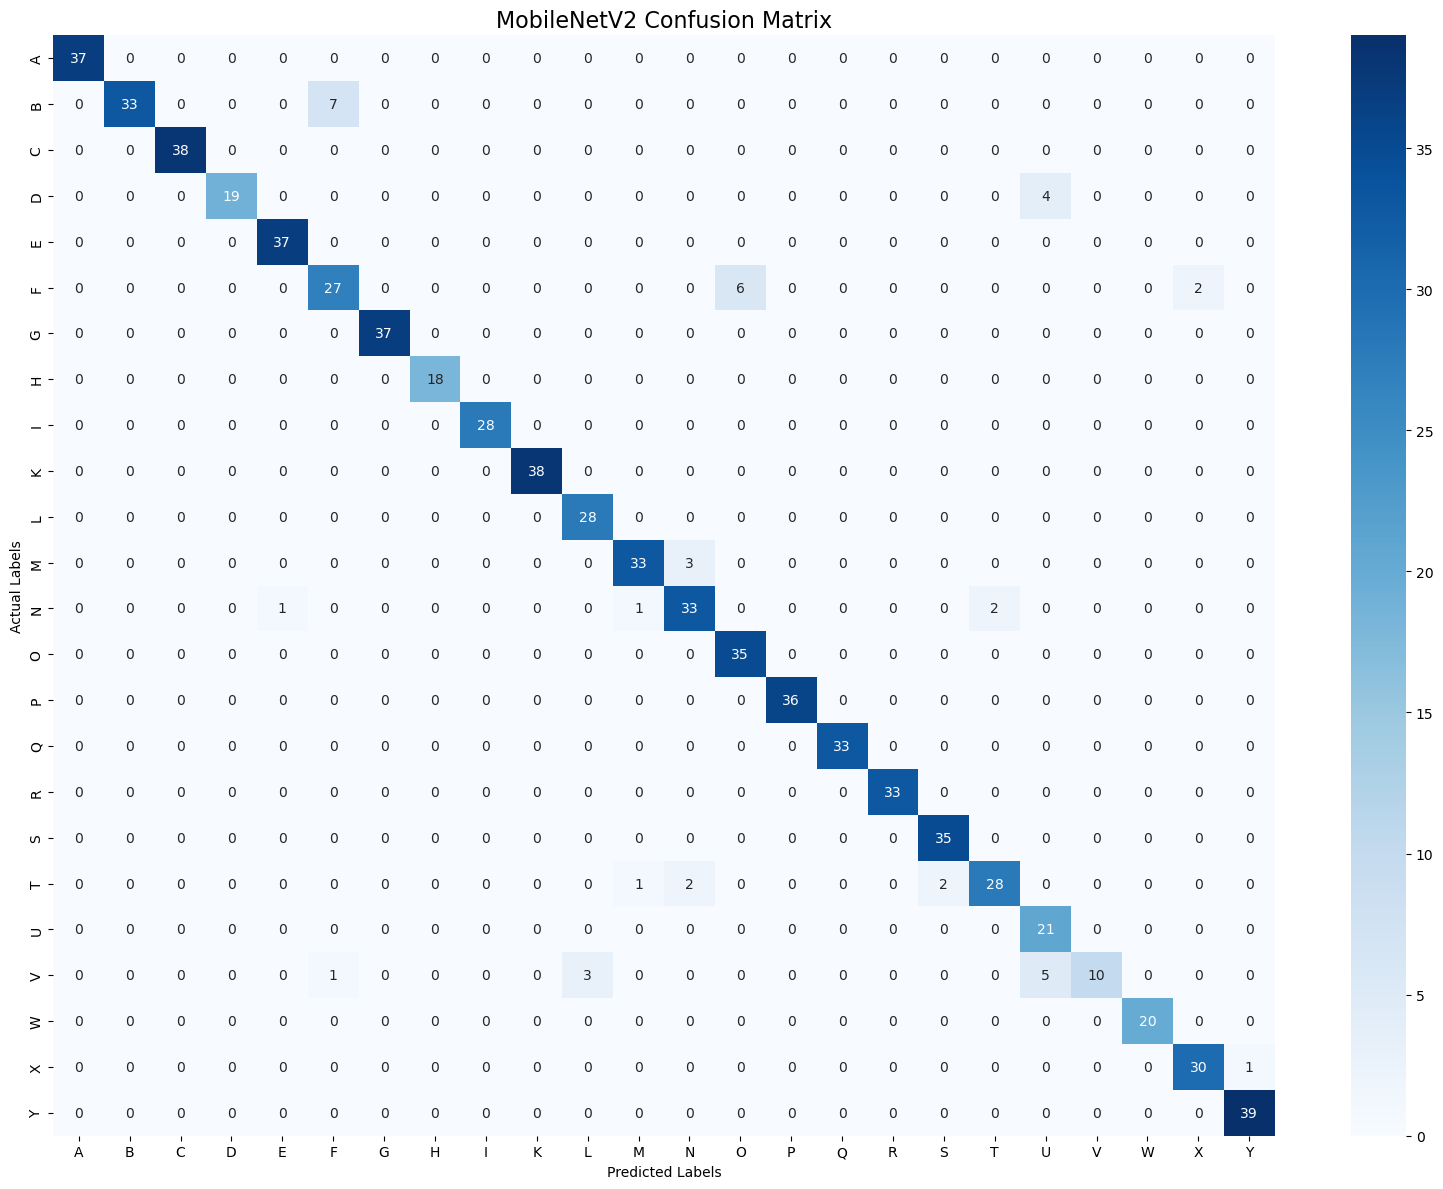

Confusion Matrix Shape: (24, 24)
Correct Predictions: 726
Incorrect Predictions: 41


In [64]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Generate confusion matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

# Visualize confusion matrix

plt.figure(figsize=(16, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("MobileNetV2 Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")

plt.tight_layout()
plt.show()

# Display matrix information

print("Confusion Matrix Shape:", cm.shape)
print("Correct Predictions:", np.trace(cm))
print("Incorrect Predictions:", cm.sum() - np.trace(cm))

In [65]:
# Analyze misclassified gesture combinations

misclassifications = []

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        if i != j and cm[i, j] > 0:

            misclassifications.append({
                "Actual Gesture": classes[i],
                "Predicted Gesture": classes[j],
                "Count": cm[i, j]
            })

# Create misclassification DataFrame

misclassification_df = pd.DataFrame(
    misclassifications
)

# Sort by highest error count

misclassification_df = (
    misclassification_df
    .sort_values("Count", ascending=False)
    .reset_index(drop=True)
)

print("Misclassification Analysis")

display(misclassification_df)

print("Total Misclassified Images:",
      misclassification_df["Count"].sum())

Misclassification Analysis


,Actual Gesture,Predicted Gesture,Count
0,B,F,7
1,F,O,6
2,V,U,5
3,D,U,4
4,M,N,3
5,V,L,3
6,F,X,2
7,N,T,2
8,T,N,2
9,T,S,2


Total Misclassified Images: 41


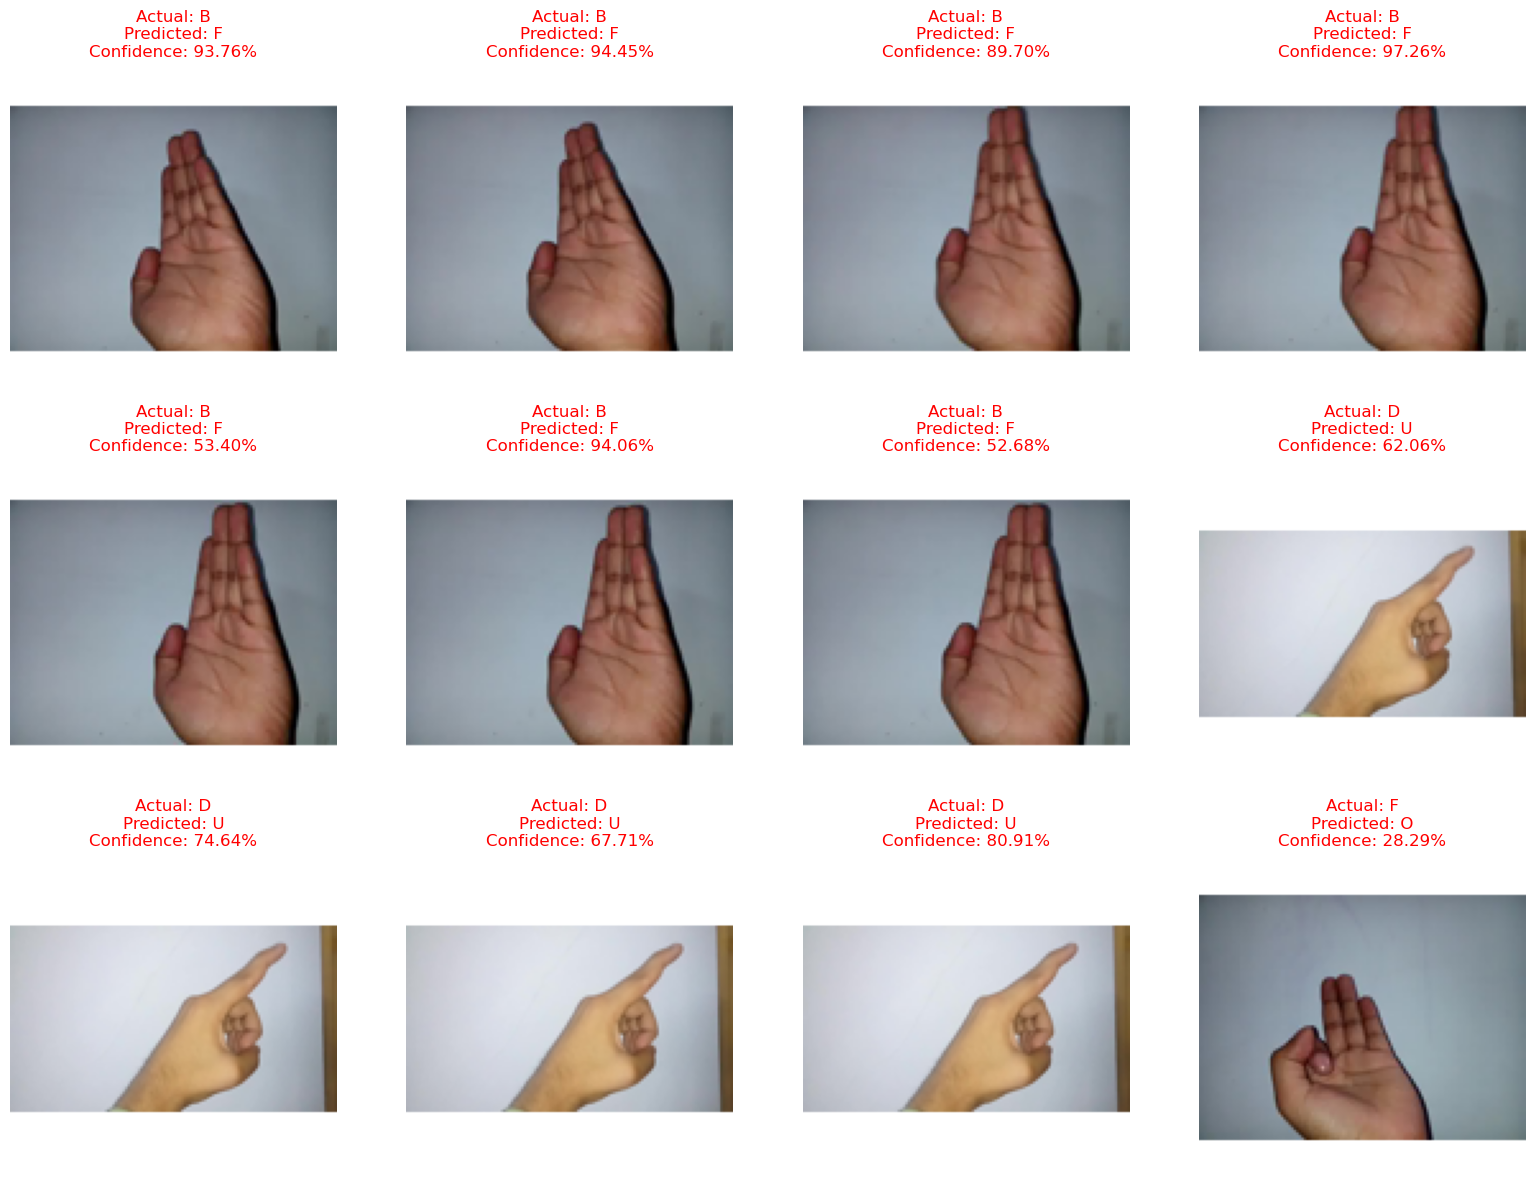

Total Misclassified Images: 41
Displayed Images: 12


In [66]:
# Identify incorrectly classified images

wrong_indices = np.where(y_true != y_pred)[0]

# Number of images to display
num_images = min(12, len(wrong_indices))

plt.figure(figsize=(16, 12))

for i in range(num_images):

    idx = wrong_indices[i]

    # Load and preprocess image
    image_path = test_df.iloc[idx]["image_path"]

    image = preprocess_image(image_path)

    # Get actual and predicted labels
    actual = classes[y_true[idx]]
    predicted = classes[y_pred[idx]]

    # Get prediction confidence
    confidence = np.max(y_pred_prob[idx]) * 100

    # Display image
    plt.subplot(3, 4, i + 1)

    plt.imshow(image)

    plt.title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Confidence: {confidence:.2f}%",
        color="red"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

print("Total Misclassified Images:", len(wrong_indices))
print("Displayed Images:", num_images)

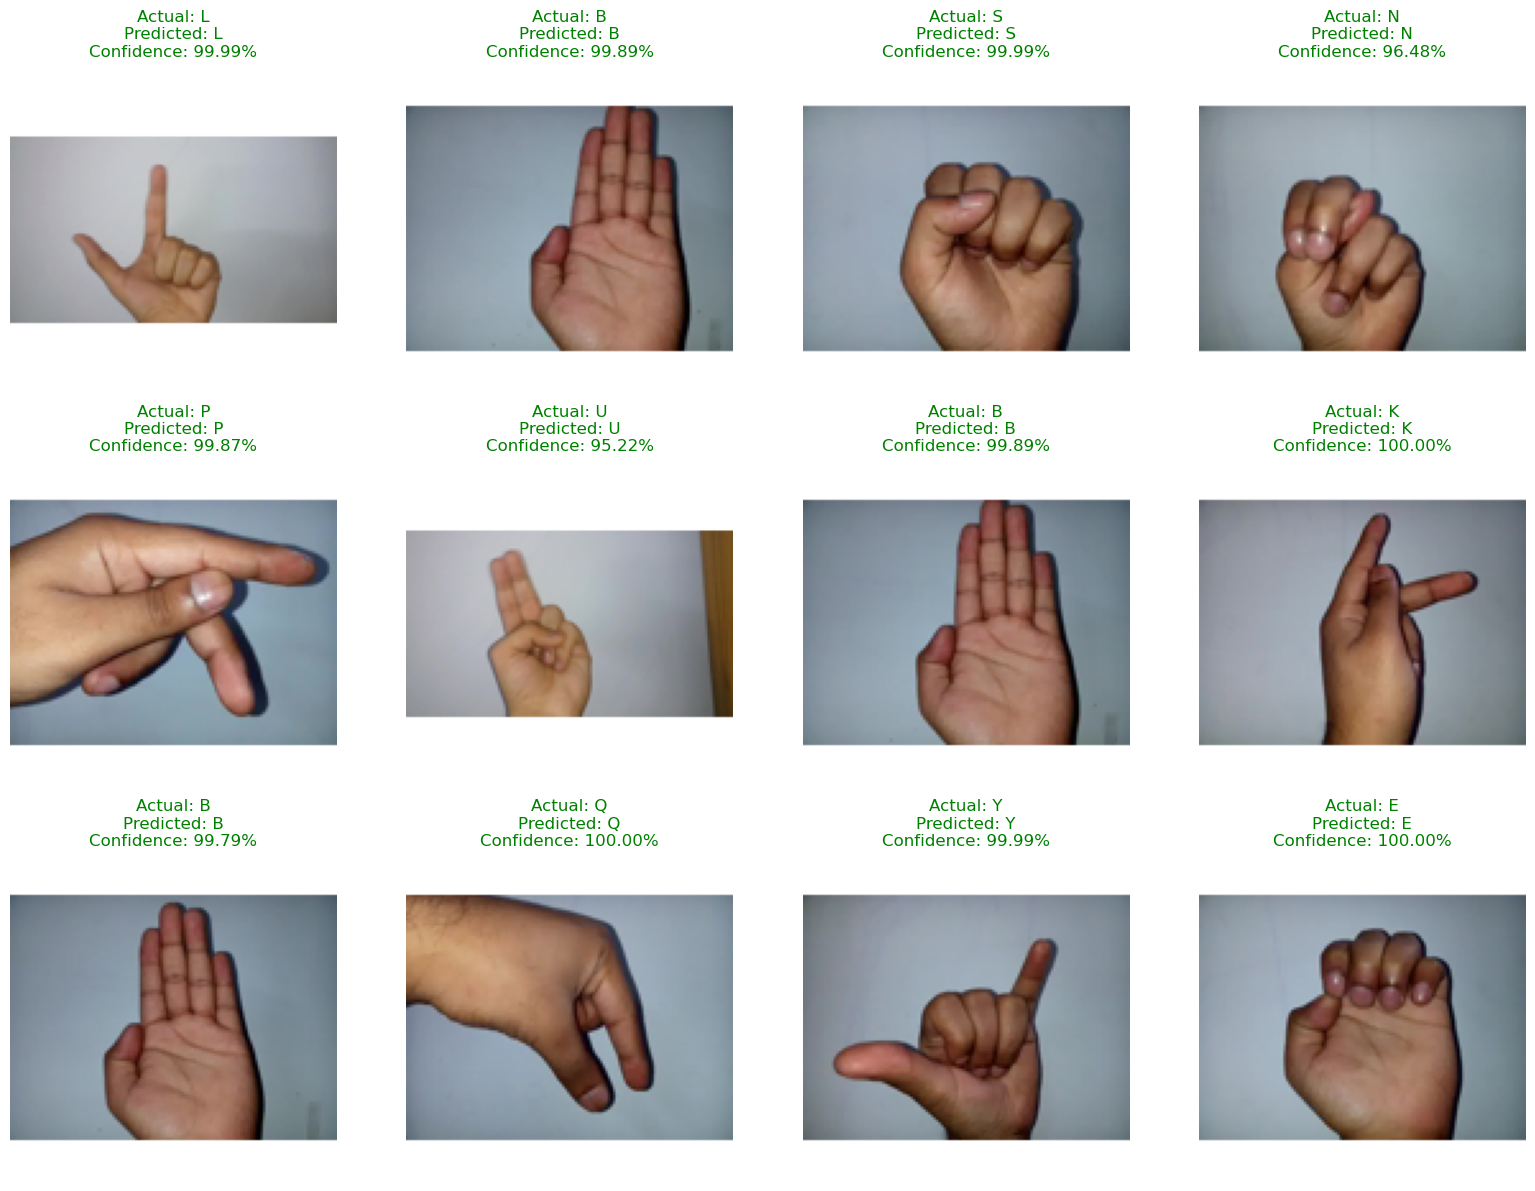

Total Correctly Classified Images: 726
Displayed Images: 12


In [67]:
# Identify correctly classified images

correct_indices = np.where(y_true == y_pred)[0]

# Randomly select 12 correct predictions
rng = np.random.default_rng(SEED)

selected_indices = rng.choice(
    correct_indices,
    size=12,
    replace=False
)

plt.figure(figsize=(16, 12))

for i, idx in enumerate(selected_indices):

    # Load and preprocess image
    image_path = test_df.iloc[idx]["image_path"]
    image = preprocess_image(image_path)

    # Get actual and predicted labels
    actual = classes[y_true[idx]]
    predicted = classes[y_pred[idx]]

    # Get prediction confidence
    confidence = np.max(y_pred_prob[idx]) * 100

    # Display image
    plt.subplot(3, 4, i + 1)

    plt.imshow(image)

    plt.title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Confidence: {confidence:.2f}%",
        color="green"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

print("Total Correctly Classified Images:",
      len(correct_indices))

print("Displayed Images:", len(selected_indices))

In [68]:
# Create single image prediction function

def predict_gesture(image_path):

    # Apply the same preprocessing used during training
    image, _ = tf_preprocess_image(
        tf.constant(str(image_path)),
        tf.constant(0)
    )

    # Add batch dimension
    input_image = tf.expand_dims(image, axis=0)

    # Generate prediction probabilities
    probabilities = final_model.predict(
        input_image,
        verbose=0
    )[0]

    # Identify predicted class
    predicted_index = np.argmax(probabilities)

    predicted_label = label_encoder.classes_[
        predicted_index
    ]

    # Calculate confidence
    confidence = float(
        probabilities[predicted_index] * 100
    )

    return predicted_label, confidence


print("Single Image Prediction Function Created Successfully")

Single Image Prediction Function Created Successfully


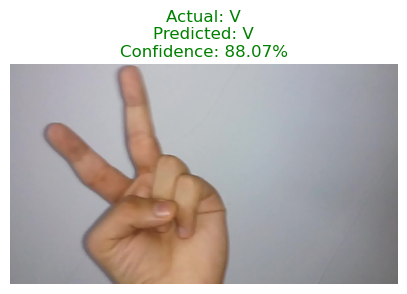

Single Image Prediction Results
----------------------------------------
Actual Gesture: V
Predicted Gesture: V
Confidence: 88.07%
Result: Correct Prediction


In [71]:
# Select a random test image

sample = test_df.sample(
    n=1,
    random_state=SEED
).iloc[0]

sample_image_path = sample["image_path"]
actual_label = sample["label"]

# Predict the gesture
predicted_label, confidence = predict_gesture(
    sample_image_path
)

# Display the image
image = Image.open(sample_image_path).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(image)

plt.title(
    f"Actual: {actual_label}\n"
    f"Predicted: {predicted_label}\n"
    f"Confidence: {confidence:.2f}%",
    color="green" if actual_label == predicted_label
    else "red"
)

plt.axis("off")
plt.show()

# Display prediction results
print("Single Image Prediction Results")
print("-" * 40)
print("Actual Gesture:", actual_label)
print("Predicted Gesture:", predicted_label)
print(f"Confidence: {confidence:.2f}%")

if actual_label == predicted_label:
    print("Result: Correct Prediction")
else:
    print("Result: Incorrect Prediction")

In [77]:
import os

print("Working Directory:", os.getcwd())

print("\nAvailable Image Files:")

for file in os.listdir():
    if file.lower().endswith((".jpg", ".jpeg", ".png")):
        print(file)

Working Directory: C:\Users\vamsi

Available Image Files:
001.jpg
002.jpg
003.jpg
004.jpg
005.jpg
006.jpg
007.jpg
008.jpg
009.jpg
010.jpg
011.jpg
012.jpg
013.jpg
014.jpg
015.jpg
016.jpg
017.jpg
019.jpg
020.jpg
021.jpg
022.jpg
023.jpg
024.jpg
025.jpg
026.jpg
027.jpg
028.jpg
029.jpg
030.jpg
031.jpg
032.jpg
033.jpg
036.jpg
037.jpg
038.jpg
039.jpg
040.jpg
041.jpg
042.jpg
043.jpg
044.jpg
045.jpg
046.jpg
047.jpg
048.jpg
049.jpg
050.jpg
051.jpg
052.jpg
053.jpg
055.jpg
057.jpg
058.jpg
059.jpg
060.jpg
061.jpg
062.jpg
063.jpg
064.jpg
065.jpg
068.jpg
069.jpg
070.jpg
071.jpg
072.jpg
073.jpg
074.jpg
075.jpg
076.jpg
077.jpg
078.jpg
079.jpg
080.jpg
083.jpg
084.jpg
085.jpg
086.jpg
087.jpg
088.jpg
089.jpg
090.jpg
091.jpg
092.jpg
093.jpg
094.jpg
098.jpg
099.jpg
100.jpg
101.jpg
102.jpg
103.jpg
104.jpg
105.jpg
106.jpg
107.jpg
108.jpg
109.jpg
110.jpg
111.jpg
112.jpg
113.jpg
114.jpg
115.jpg
116.jpg
117.jpg
118.jpg
119.jpg
120.jpg
121.jpg
123.jpg
124.jpg
125.jpg
126.jpg
127.jpg
128.jpg
129.jpg
130.jpg
131.jp

In [78]:
# Save the final trained model

final_model_path = "ISL_Final_MobileNetV2.keras"

final_model.save(final_model_path)

print("Final Model Saved Successfully")
print("Model Name:", final_model_name)
print("File Name:", final_model_path)
print("File Exists:", os.path.exists(final_model_path))

# Calculate model file size
file_size = os.path.getsize(final_model_path) / (1024 ** 2)

print(f"Model File Size: {file_size:.2f} MB")

Final Model Saved Successfully
Model Name: MobileNetV2
File Name: ISL_Final_MobileNetV2.keras
File Exists: True
Model File Size: 11.11 MB


In [79]:
# Save class labels

import json

class_labels = label_encoder.classes_.tolist()

class_labels_path = "ISL_Class_Labels.json"

with open(class_labels_path, "w") as file:
    json.dump(class_labels, file, indent=4)

print("Class Labels Saved Successfully")
print("File Name:", class_labels_path)
print("Total Classes:", len(class_labels))
print("Class Labels:", class_labels)
print("File Exists:", os.path.exists(class_labels_path))

Class Labels Saved Successfully
File Name: ISL_Class_Labels.json
Total Classes: 24
Class Labels: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']
File Exists: True


In [80]:
# Load the saved model

loaded_model = tf.keras.models.load_model(
    "ISL_Final_MobileNetV2.keras"
)

# Load the saved class labels

with open("ISL_Class_Labels.json", "r") as file:
    loaded_class_labels = json.load(file)

# Verify model and class labels

print("Model Loaded Successfully")
print("Model Name:", loaded_model.name)
print("Input Shape:", loaded_model.input_shape)
print("Output Shape:", loaded_model.output_shape)
print("Total Parameters:", loaded_model.count_params())

print("\nClass Labels Loaded Successfully")
print("Total Classes:", len(loaded_class_labels))
print("Class Labels:", loaded_class_labels)

# Verify class count

print("\nModel and Class Labels Match:",
      loaded_model.output_shape[-1] == len(loaded_class_labels))

print("Class Order Match:",
      loaded_class_labels == label_encoder.classes_.tolist())

Model Loaded Successfully
Model Name: ISL_MobileNetV2_Model
Input Shape: (None, 128, 128, 3)
Output Shape: (None, 24)
Total Parameters: 2425048

Class Labels Loaded Successfully
Total Classes: 24
Class Labels: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']

Model and Class Labels Match: True
Class Order Match: True


In [81]:
# Evaluate the reloaded model

loaded_test_loss, loaded_test_accuracy = loaded_model.evaluate(
    test_ds,
    verbose=1
)

print("\nReloaded Model Evaluation")
print("-" * 40)

print(f"Original Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Reloaded Test Accuracy: {loaded_test_accuracy * 100:.2f}%")

print(f"Original Test Loss: {test_loss:.4f}")
print(f"Reloaded Test Loss: {loaded_test_loss:.4f}")

# Verify performance consistency

accuracy_match = np.isclose(
    test_accuracy,
    loaded_test_accuracy,
    atol=1e-6
)

loss_match = np.isclose(
    test_loss,
    loaded_test_loss,
    atol=1e-6
)

print("\nAccuracy Match:", accuracy_match)
print("Loss Match:", loss_match)

if accuracy_match and loss_match:
    print("Model Verification Successful")
else:
    print("Performance Difference Detected")

24/24 ━━━━━━━━━━━━━━━━━━━━ 18s 514ms/step - accuracy: 0.9465 - loss: 0.1549

Reloaded Model Evaluation
----------------------------------------
Original Test Accuracy: 94.65%
Reloaded Test Accuracy: 94.65%
Original Test Loss: 0.1549
Reloaded Test Loss: 0.1549

Accuracy Match: True
Loss Match: True
Model Verification Successful


In [82]:
# Prediction using the saved model

def predict_saved_model(image_path):

    # Preprocess the input image
    image, _ = tf_preprocess_image(
        tf.constant(str(image_path)),
        tf.constant(0)
    )

    # Add batch dimension
    input_image = tf.expand_dims(image, axis=0)

    # Predict using the loaded model
    probabilities = loaded_model.predict(
        input_image,
        verbose=0
    )[0]

    predicted_index = np.argmax(probabilities)

    predicted_label = loaded_class_labels[
        predicted_index
    ]

    confidence = float(
        probabilities[predicted_index] * 100
    )

    return predicted_label, confidence


# Test the saved model
predicted_label, confidence = predict_saved_model(
    sample_image_path
)

print("Saved Model Prediction Results")
print("-" * 40)
print("Actual Gesture:", actual_label)
print("Predicted Gesture:", predicted_label)
print(f"Confidence: {confidence:.2f}%")

if actual_label == predicted_label:
    print("Result: Correct Prediction")
else:
    print("Result: Incorrect Prediction")

Saved Model Prediction Results
----------------------------------------
Actual Gesture: V
Predicted Gesture: V
Confidence: 88.07%
Result: Correct Prediction


In [83]:
# Final project performance summary

final_summary = pd.DataFrame({
    "Parameter": [
        "Final Model",
        "Total Images",
        "Training Images",
        "Validation Images",
        "Testing Images",
        "Total Classes",
        "Validation Accuracy",
        "Test Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score",
        "Test Loss",
        "Correct Predictions",
        "Incorrect Predictions",
        "Total Model Parameters",
        "Model File Size"
    ],

    "Result": [
        final_model_name,
        len(df),
        len(train_df),
        len(val_df),
        len(test_df),
        NUM_CLASSES,
        f"{transfer_val_accuracy * 100:.2f}%",
        f"{test_accuracy * 100:.2f}%",
        f"{precision * 100:.2f}%",
        f"{recall * 100:.2f}%",
        f"{f1 * 100:.2f}%",
        f"{test_loss:.4f}",
        len(correct_indices),
        len(wrong_indices),
        final_model.count_params(),
        f"{file_size:.2f} MB"
    ]
})

print("FINAL PROJECT PERFORMANCE SUMMARY")
display(final_summary)

FINAL PROJECT PERFORMANCE SUMMARY


,Parameter,Result
0,Final Model,MobileNetV2
1,Total Images,4971
2,Training Images,3468
3,Validation Images,736
4,Testing Images,767
5,Total Classes,24
6,Validation Accuracy,99.46%
7,Test Accuracy,94.65%
8,Macro Precision,95.02%
9,Macro Recall,94.06%


## Project Challenges and Limitations

### Challenges and Solutions

1. Different Image Dimensions
   - Images had different resolutions and orientations.
   - Resized all images to 128 × 128 pixels while
     preserving aspect ratio using padding.

2. Class Imbalance
   - Some gesture classes contained fewer images.
   - Applied balanced class weights during training.

3. Duplicate Images
   - Identified one exact duplicate image using SHA-256.
   - Removed the duplicate before splitting the dataset.

4. Similar Hand Gestures
   - Some alphabet gestures had similar hand positions.
   - Used MobileNetV2 for improved feature extraction.

5. Low Baseline Model Performance
   - The baseline CNN achieved 30.84% validation accuracy.
   - Transfer learning improved validation accuracy
     to 99.46%.

6. Computational Limitations
   - Model training was performed using a CPU.
   - Used a lightweight pretrained MobileNetV2 model.

### Project Limitations

- The model recognizes only 24 alphabet gesture classes.
- Letters J and Z are unavailable in the dataset.
- Similar gestures may cause incorrect predictions.
- External image performance has not been verified.
- Sequential images may contain near-duplicate frames
  across dataset splits.
- Generalization to new signers, backgrounds and lighting
  conditions requires further testing.
- The model does not support continuous sign language
  translation.

## Future Enhancements

1. Dataset Expansion
   - Collect more images from different signers.
   - Include missing alphabet gestures J and Z.

2. Improved Model Accuracy
   - Explore fine-tuning of MobileNetV2.
   - Compare advanced architectures such as
     EfficientNet and ResNet50.

3. Real-Time Gesture Recognition
   - Integrate OpenCV for webcam-based recognition.
   - Develop real-time gesture prediction.

4. Hand Detection and Tracking
   - Integrate MediaPipe for hand landmark detection.
   - Reduce background interference.

5. Continuous Sign Language Recognition
   - Explore LSTM and Transformer architectures
     for dynamic gesture recognition.

6. Application Deployment
   - Develop a user-friendly Streamlit application.
   - Support image uploads and gesture predictions.

7. Text and Speech Conversion
   - Convert recognized gestures into text.
   - Integrate text-to-speech functionality.

8. Real-World Validation
   - Test with independent signers, different
     backgrounds and lighting conditions.
   - Validate gesture labels with ISL experts.

## Project Conclusion

The Indian Sign Language Recognition project was
successfully developed using deep learning and
transfer learning techniques.

The original dataset contained 4,972 images across
24 alphabet gesture classes. After removing one
duplicate image, 4,971 images were used for training,
validation and testing.

Image preprocessing techniques, including resizing,
normalization, data augmentation and class weighting,
were applied during model development.

Two deep learning models were developed and compared:

- Baseline CNN: 30.84% validation accuracy.
- MobileNetV2: 99.46% validation accuracy.

MobileNetV2 was selected as the final model based
on its superior validation performance.

### Final Model Results

- Test Accuracy: 94.65%
- Macro Precision: 95.02%
- Macro Recall: 94.06%
- Macro F1-Score: 94.00%
- Correct Predictions: 726
- Incorrect Predictions: 41

The final trained model and class labels were
successfully saved, reloaded and verified.

The project demonstrates the potential of transfer
learning for alphabet gesture recognition and
assistive communication applications.

However, further testing with independent signers
and external images is required before real-world
deployment.

In [84]:
# Verify important project files

project_files = [
    "Indian_Sign_Language_Recognition.ipynb",
    "best_isl_model.keras",
    "best_mobilenetv2_model.keras",
    "ISL_Final_MobileNetV2.keras",
    "ISL_Class_Labels.json"
]

print("FINAL PROJECT FILE VERIFICATION")
print("-" * 50)

for file in project_files:

    if os.path.exists(file):
        size = os.path.getsize(file) / (1024 ** 2)
        print(f"{file} | Available | {size:.2f} MB")
    else:
        print(f"{file} | Not Found")

FINAL PROJECT FILE VERIFICATION
--------------------------------------------------
Indian_Sign_Language_Recognition.ipynb | Available | 6.49 MB
best_isl_model.keras | Available | 1.35 MB
best_mobilenetv2_model.keras | Available | 11.11 MB
ISL_Final_MobileNetV2.keras | Available | 11.11 MB
ISL_Class_Labels.json | Available | 0.00 MB


In [85]:
# Create results folder

results_folder = "ISL_Project_Results"

os.makedirs(results_folder, exist_ok=True)

# Export final performance summary
final_summary.to_csv(
    os.path.join(results_folder, "Final_Performance.csv"),
    index=False
)

# Export model comparison
model_comparison.to_csv(
    os.path.join(results_folder, "Model_Comparison.csv"),
    index=False
)

# Export misclassification analysis
misclassification_df.to_csv(
    os.path.join(results_folder, "Misclassification_Analysis.csv"),
    index=False
)

# Export confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=classes,
    columns=classes
)

cm_df.to_csv(
    os.path.join(results_folder, "Confusion_Matrix.csv")
)

# Export classification report
with open(
    os.path.join(results_folder, "Classification_Report.txt"),
    "w"
) as file:
    file.write(report)

print("Project Results Exported Successfully")

print("\nExported Files:")

for file in sorted(os.listdir(results_folder)):
    print(file)

Project Results Exported Successfully

Exported Files:
Classification_Report.txt
Confusion_Matrix.csv
Final_Performance.csv
Misclassification_Analysis.csv
Model_Comparison.csv


In [86]:
%pip install streamlit

  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.36.2
    Uninstalling protobuf-7.36.2:
      Successfully uninstalled protobuf-7.36.2
Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.


In [87]:
%%writefile app.py

import streamlit as st
import tensorflow as tf
import numpy as np
import json
from PIL import Image

# Configure application
st.set_page_config(
    page_title="Indian Sign Language Recognition",
    page_icon="🤟",
    layout="centered"
)

# Application title
st.title("Indian Sign Language Recognition")

st.write(
    "Upload a hand gesture image to predict "
    "the corresponding alphabet."
)

Writing app.py


In [88]:
%%writefile -a app.py

# Load trained model and class labels

@st.cache_resource
def load_model_and_labels():

    model = tf.keras.models.load_model(
        "ISL_Final_MobileNetV2.keras",
        compile=False
    )

    with open("ISL_Class_Labels.json", "r") as file:
        class_labels = json.load(file)

    return model, class_labels


model, class_labels = load_model_and_labels()

st.success("Model loaded successfully!")

st.write("Supported Gesture Classes:", len(class_labels))

Appending to app.py


In [89]:
%%writefile -a app.py

# Image preprocessing function

def preprocess_uploaded_image(uploaded_file):

    # Read uploaded image
    image_bytes = uploaded_file.getvalue()

    # Decode image into RGB format
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    # Normalize pixel values
    image = tf.cast(image, tf.float32) / 255.0

    # Resize with white padding
    image = 1.0 - tf.image.resize_with_pad(
        1.0 - image,
        128,
        128
    )

    # Set image shape
    image.set_shape((128, 128, 3))

    # Add batch dimension
    image = tf.expand_dims(image, axis=0)

    return image

Appending to app.py


In [90]:
%%writefile -a app.py

# Gesture prediction function

def predict_gesture(uploaded_file):

    # Preprocess uploaded image
    processed_image = preprocess_uploaded_image(
        uploaded_file
    )

    # Generate prediction probabilities
    probabilities = model.predict(
        processed_image,
        verbose=0
    )[0]

    # Identify predicted class
    predicted_index = np.argmax(probabilities)

    predicted_label = class_labels[predicted_index]

    # Calculate confidence score
    confidence = float(
        probabilities[predicted_index] * 100
    )

    return predicted_label, confidence

Appending to app.py


In [91]:
%%writefile -a app.py

# Application interface

st.divider()

uploaded_file = st.file_uploader(
    "Upload a hand gesture image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:

    try:
        image = Image.open(uploaded_file).convert("RGB")

        st.image(
            image,
            caption="Uploaded Gesture Image",
            width=300
        )

        if st.button("Predict Gesture", type="primary"):

            with st.spinner("Predicting gesture..."):

                predicted_label, confidence = predict_gesture(
                    uploaded_file
                )

            st.subheader("Prediction Results")

            col1, col2 = st.columns(2)

            with col1:
                st.metric("Predicted Gesture", predicted_label)

            with col2:
                st.metric("Confidence", f"{confidence:.2f}%")

            st.progress(min(confidence / 100, 1.0))

    except Exception:
        st.error("Unable to process the image.")

else:
    st.info("Please upload a hand gesture image.")

# Sidebar information

st.sidebar.header("About the Project")

st.sidebar.write("Model: MobileNetV2")
st.sidebar.write("Test Accuracy: 94.65%")
st.sidebar.write("Validation Accuracy: 99.46%")
st.sidebar.write("Supported Classes: 24")

st.sidebar.write(", ".join(class_labels))

st.sidebar.warning(
    "External image performance is not yet verified."
)

st.divider()

st.caption(
    "Indian Sign Language Recognition | AI Capstone Project"
)


Appending to app.py


In [94]:
import os

print("Working Directory:", os.getcwd())
print("Application Path:", os.path.abspath("app.py"))
print("File Exists:", os.path.exists("app.py"))

Working Directory: C:\Users\vamsi
Application Path: C:\Users\vamsi\app.py
File Exists: True


In [95]:
import sys

print("Python Path:", sys.executable)

Python Path: C:\Users\vamsi\anaconda3\python.exe


In [96]:
import sys

print("Python Path:", sys.executable)

Python Path: C:\Users\vamsi\anaconda3\python.exe


In [97]:
import shutil
import os

submission_folder = "PRAICP-1000-IndiSignLang"

os.makedirs(submission_folder, exist_ok=True)

files = [
    "Indian_Sign_Language_Recognition.ipynb",
    "ISL_Final_MobileNetV2.keras",
    "ISL_Class_Labels.json",
    "app.py"
]

for file in files:
    shutil.copy2(file, submission_folder)

shutil.copytree(
    "ISL_Project_Results",
    os.path.join(submission_folder, "ISL_Project_Results"),
    dirs_exist_ok=True
)

zip_path = shutil.make_archive(
    submission_folder,
    "zip",
    submission_folder
)

print("Submission ZIP Created Successfully")
print("ZIP Location:", zip_path)

Submission ZIP Created Successfully
ZIP Location: C:\Users\vamsi\PRAICP-1000-IndiSignLang.zip


In [99]:
import nbformat
import os
import base64
import io
from PIL import Image

notebook = nbformat.read(
    "ISL_Final_Submission.ipynb",
    as_version=4
)

# Compress embedded images
for cell in notebook.cells:

    if cell.cell_type == "code":

        for output in cell.get("outputs", []):

            data = output.get("data", {})

            if "image/png" in data:

                image_bytes = base64.b64decode(
                    data["image/png"]
                )

                image = Image.open(
                    io.BytesIO(image_bytes)
                ).convert("RGB")

                image.thumbnail((1000, 1000))

                buffer = io.BytesIO()

                image.save(
                    buffer,
                    format="JPEG",
                    quality=75,
                    optimize=True
                )

                data["image/jpeg"] = base64.b64encode(
                    buffer.getvalue()
                ).decode("utf-8")

                del data["image/png"]

# Save compressed notebook
submission_file = "ISL_Final_Submission.ipynb"

nbformat.write(notebook, submission_file)

size = os.path.getsize(submission_file)

print("Notebook Compressed Successfully")
print("Submission File:", submission_file)
print(f"File Size: {size / 1024**2:.2f} MB")
print("Ready for Upload:", size < 5000000)

Notebook Compressed Successfully
Submission File: ISL_Final_Submission.ipynb
File Size: 1.05 MB
Ready for Upload: True
